# Variable Selection for cGAN Background Modelling

Exploratory study of large-*R* jet variables in simulated ATLAS H→bb̄ signal and QCD multijet background.
The aim is to find variables that are **correlated with jet mass** (so they can predict it) but have **similar signal and background shapes** (so conditioning on them does not sculpt a fake signal).
The selected *Category A* variables are used as conditioning inputs in `02_conditional_gan.ipynb`.

---

## Setup: Import Libraries and Load Data

**Note**: This section reuses code from `gp_intro.ipynb`

In [2]:
# Import required libraries
import uproot              # For reading ROOT files
import matplotlib.pyplot as plt  # For plotting
import awkward as ak       # For irregular nested arrays
import numpy as np         # For numerical operations
import matplotlib as mpl
from scipy.stats import binned_statistic  # For histogram binning
import pandas as pd        # For data manipulation
import seaborn as sns      # For nice correlation plots

# Configure plotting
plt.rcParams["figure.dpi"] = 150  # High resolution plots
plt.rcParams["figure.figsize"] = (10, 6)  # Default figure size
# plt.rcParams["text.usetex"] = True  # Uncomment if you have LaTeX installed

### Define Field Aliases

**FROM gp_intro.ipynb**: We use short aliases for long ROOT branch names

In [3]:
# Dictionary mapping long ROOT branch names to short aliases
# This makes the code more readable
field_aliases = {
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetMass": "jet_mass",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetPt": "jet_pt",  # NEW: pT variable
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GN2Xv01_phbb": "jet_phbb",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GhostBHadronsFinal": "jet_num_bhad",
}

# Extract just the branch names (keys) for loading
fields = list(field_aliases.keys())

print("Variables to load:")
for original, alias in field_aliases.items():
    print(f"  {alias} <- {original}")

Variables to load:
  jet_mass <- AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetMass
  jet_pt <- AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetPt
  jet_phbb <- AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GN2Xv01_phbb
  jet_num_bhad <- AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GhostBHadronsFinal


### Load Data Files

**FROM gp_intro.ipynb**: Load signal and background ROOT files

**Note**: Update these paths to match your data location!

In [4]:
path_bkg = "./background/*.root:CollectionTree"
path_sig = "./signal/*.root:CollectionTree"

print("Loading background data...")
data_bkg = uproot.concatenate(path_bkg, fields, library="ak")
print(f"  Loaded {len(data_bkg)} background events")

print("\nLoading signal data...")
data_sig = uproot.concatenate(path_sig, fields, library="ak")
print(f"  Loaded {len(data_sig)} signal events")

Loading background data...
  Loaded 80000 background events

Loading signal data...
  Loaded 40000 signal events


### Rename Fields

**FROM gp_intro.ipynb**: Apply short aliases to make data access easier

In [5]:
def rename_fields(data):
    """
    Replace long ROOT branch names with short aliases.
    
    Parameters:
    -----------
    data : awkward.Array
        Input data with original field names
    
    Returns:
    --------
    awkward.Array
        Data with renamed fields
    """
    # Create new fields with short names
    for field, alias in field_aliases.items():
        data[alias] = data[field]
    
    # Keep only the aliased fields
    data = data[list(field_aliases.values())]
    return data

# Apply renaming
data_sig = rename_fields(data_sig)
data_bkg = rename_fields(data_bkg)

print("Available fields after renaming:")
print(data_sig.fields)

Available fields after renaming:
['jet_mass', 'jet_pt', 'jet_phbb', 'jet_num_bhad']


### Define Plotting Function

**FROM gp_intro.ipynb**: Reuse the histogram plotting function with error bands

In [6]:
def plot_histogram(x, bins, ax, color, label=None, linewidth=1.0):
    """
    Plot a histogram with Poisson error bands.
    
    This function creates a step-style histogram where each bin is drawn
    as a horizontal line, with a shaded region representing statistical uncertainty.
    
    Parameters:
    -----------
    x : array-like
        Data values to histogram
    bins : array-like
        Bin edges (length N+1 for N bins)
    ax : matplotlib.axes.Axes
        Axes object to plot on
    color : str
        Color for the histogram line and error band
    label : str, optional
        Label for the legend
    linewidth : float, optional
        Width of the histogram line
    
    Statistical Note:
    -----------------
    Error bars represent Poisson uncertainty: σ = 1/√n
    where n is the number of events in each bin.
    """
    # Calculate bin centers for plotting
    bin_centres = (bins[1:] + bins[:-1]) / 2
    
    # Count events in each bin
    n, _, _ = binned_statistic(x, x, statistic="count", bins=bins)
    
    # Calculate Poisson error: σ = 1/√n
    # Adding a small epsilon to avoid division by zero
    n_err = 1 / np.sqrt(n + 1e-10)
    
    # Normalize to probability density
    n_total = np.sum(n)
    n = n / n_total
    n_err = n_err / n_total
    
    # Plot each bin as a horizontal line segment
    for bin_idx in range(len(bins)-1):
        # Bin edges
        px = np.array([bins[bin_idx], bins[bin_idx+1]])
        # Bin height (same for both edges to make horizontal line)
        py = np.array([n[bin_idx], n[bin_idx]])
        # Error (same for both edges)
        pe = np.array([n_err[bin_idx], n_err[bin_idx]])
        
        # Plot the central value
        if bin_idx == 0 and label:  # Only add label to first segment
            ax.plot(px, py, color=color, linewidth=linewidth, label=label)
        else:
            ax.plot(px, py, color=color, linewidth=linewidth)
        
        # Plot the error band (shaded region)
        ax.fill_between(px, py - pe, py + pe, color=color, alpha=0.15, ec="none")

### Helper Function: Extract Leading Jet Variable

**NEW FUNCTION**: Generalizes the leading jet extraction from gp_intro.ipynb

In [7]:
def get_leading_jet_variable(data, variable_name, unit_conversion=1.0):
    """
    Extract the leading (highest pT) jet's value for a given variable.
    
    In each collision event, multiple jets can be produced. We select the
    "leading jet" - the one with highest transverse momentum (pT) - as it's
    most likely to come from the physics process we're interested in.
    
    Parameters:
    -----------
    data : awkward.Array
        Dataset containing jet variables
    variable_name : str
        Name of the variable to extract (e.g., 'jet_mass', 'jet_pt')
    unit_conversion : float, optional
        Conversion factor (e.g., 1000.0 to convert MeV to GeV)
    
    Returns:
    --------
    numpy.ndarray
        1D array of the leading jet's variable values
    
    Example:
    --------
    Event structure:
        Event 0: [jet1(pT=100), jet2(pT=80), jet3(pT=60)]  → select jet1
        Event 1: [jet1(pT=120), jet2(pT=90)]               → select jet1
        Event 2: [jet1(pT=70)]                             → select jet1
    """
    # Get the variable values for all jets
    var_values = data[variable_name] / unit_conversion
    
    # Find index of jet with maximum pT in each event
    # axis=-1: operate along the jet dimension
    # keepdims=True: maintain array structure for indexing
    leading_idx = ak.argmax(data["jet_pt"], axis=-1, keepdims=True)
    
    # Extract the variable value for the leading jet
    leading_var = var_values[leading_idx]
    
    # Flatten from [[value]] to [value] and fill any None values with -1
    leading_var = ak.fill_none(ak.flatten(leading_var, axis=-1), -1)
    
    # Convert to numpy array for easier manipulation
    return ak.to_numpy(leading_var)

# Test the function
test_mass = get_leading_jet_variable(data_sig, "jet_mass", 1000.0)
print(f"Extracted {len(test_mass)} leading jet masses")
print(f"Example values: {test_mass[:5]}")

Extracted 40000 leading jet masses
Example values: [ 14.77491188 141.87219238 128.18981934 131.29905701  44.01802444]


---

# Question 1: Plot Jet Transverse Momentum (pT)

## Background: What is pT?

**Transverse momentum (pT)** is the component of momentum perpendicular to the beam axis.

- **Why it matters**: 
  - Conservation of momentum in the transverse plane
  - Before collision: pT = 0 (protons moving parallel to beam)
  - After collision: ΣpT should still ≈ 0
  - High pT jets indicate hard scattering (interesting physics!)

- **Units**: Typically measured in GeV/c (we'll use GeV for simplicity)

## Task

Plot the pT distribution for **leading jets only** in both signal and background datasets.

### Variable Name
- Full name: `AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetPt`
- Alias: `jet_pt`

In [8]:
# Extract leading jet pT for both signal and background
# Units: MeV in ROOT files, convert to GeV by dividing by 1000

print("Extracting leading jet pT...")
leading_pt_sig = get_leading_jet_variable(data_sig, "jet_pt", 1000.0)
leading_pt_bkg = get_leading_jet_variable(data_bkg, "jet_pt", 1000.0)

print(f"Signal: {len(leading_pt_sig)} events")
print(f"  pT range: [{leading_pt_sig.min():.1f}, {leading_pt_sig.max():.1f}] GeV")
print(f"  Mean pT: {leading_pt_sig.mean():.1f} GeV")

print(f"\nBackground: {len(leading_pt_bkg)} events")
print(f"  pT range: [{leading_pt_bkg.min():.1f}, {leading_pt_bkg.max():.1f}] GeV")
print(f"  Mean pT: {leading_pt_bkg.mean():.1f} GeV")

Extracting leading jet pT...
Signal: 40000 events
  pT range: [-1.0, 1190.3] GeV
  Mean pT: 270.5 GeV

Background: 80000 events
  pT range: [-1.0, 1369.3] GeV
  Mean pT: 479.0 GeV


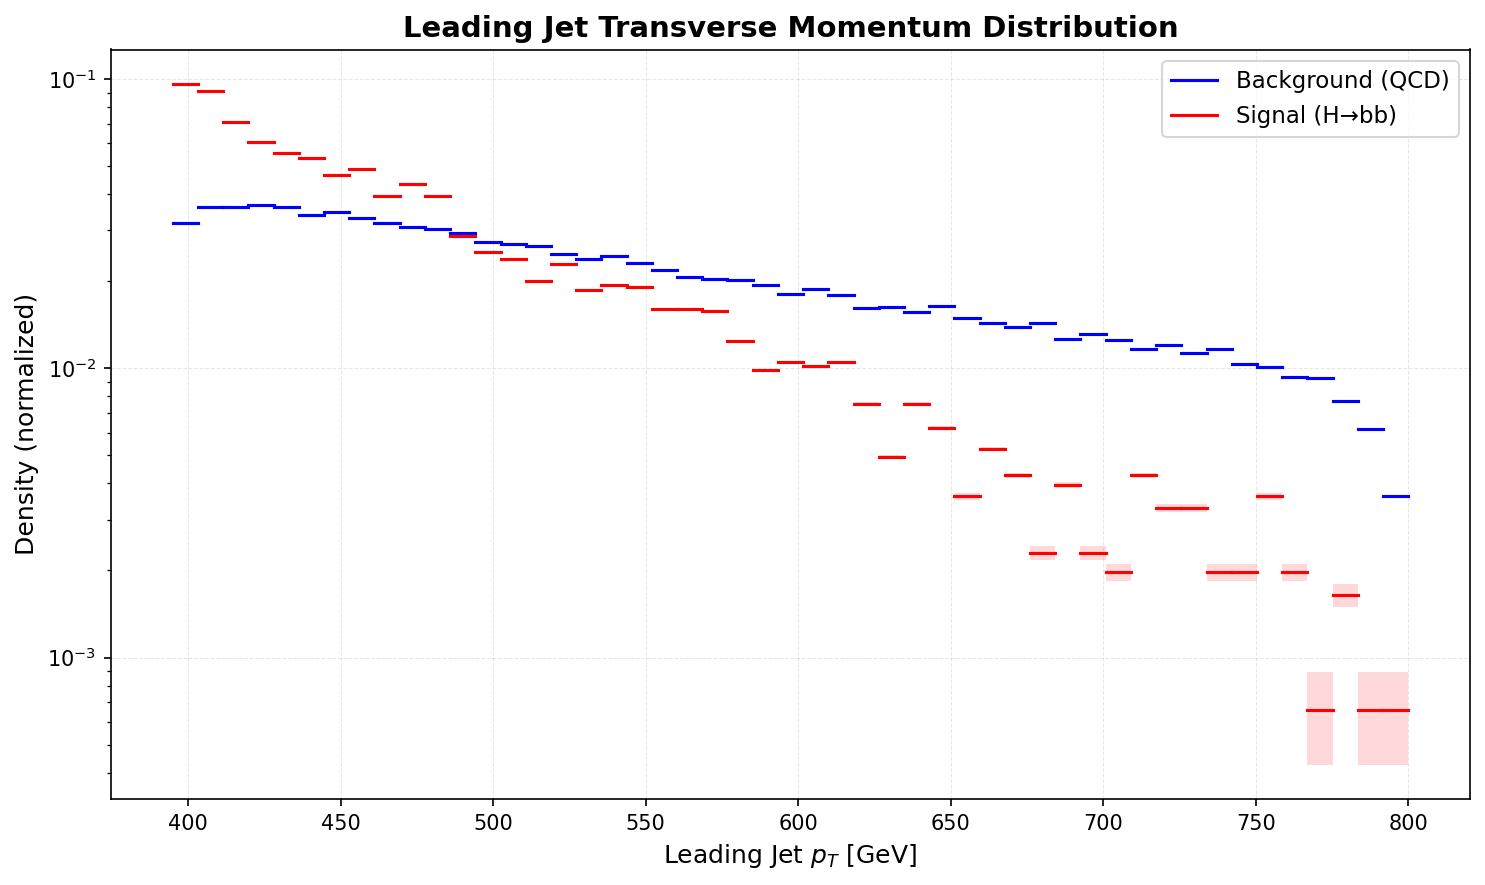

In [20]:
# Create the pT distribution plot
fig, ax = plt.subplots(figsize=(10, 6))

# Define bins for pT (typical range: 200-2000 GeV)
# Using 50 bins provides good resolution without too much statistical noise
bins_pt = np.linspace(395, 800, 50)

# bins_pt = np.linspace(0, 500, 50)
# Plot background (blue)
plot_histogram(leading_pt_bkg, bins_pt, ax, color="blue", 
               label="Background (QCD)", linewidth=1.5)

# Plot signal (red)
plot_histogram(leading_pt_sig, bins_pt, ax, color="red", 
               label="Signal (H→bb)", linewidth=1.5)

# Use log scale for y-axis (events span several orders of magnitude)
ax.set_yscale("log")

# Styling
ax.grid(True, alpha=0.3, linestyle="--", linewidth=0.5)
ax.set_xlabel(r"Leading Jet $p_T$ [GeV]", fontsize=12)
ax.set_ylabel("Density (normalized)", fontsize=12)
ax.set_title("Leading Jet Transverse Momentum Distribution", fontsize=14, fontweight='bold')
ax.legend(loc="upper right", fontsize=11)

plt.tight_layout()
plt.show()

### Observations: pT alone isn't enough!!

 
1. **Similarity**: 
   - Signal and background have similar pT distributions,has heavy overlap,both fall off at high pT
   
2. **Slight Difference**:
   -  Background extends to slightly higher pT, helpful when combined with other variables (This motivates multivariate analysis!)


---

# Question 2: Correlation Analysis

## Background: Pearson correlation coefficient

**Pearson correlation coefficient (r)** measures linear relationship between two variables:


$$
\mathbf{r = \frac{\mathrm{Cov}(X,Y)}{\sigma_X \, \sigma_Y}}
$$


- **r = +1**: Perfect positive correlation (X↑ → Y↑)
- **r = 0**: No correlation (independent)
- **r = -1**: Perfect negative correlation (X↑ → Y↓)


## Task
look at correlation：Next step is to look at correlations between the variables. Create a function that can create a correlation matrix between a list of varaibles. Plot the correlation between mass and pT for signal and background separately.）

1. Create a function to compute correlation matrix （def compute_correlation_matrix）
2. Plot correlation between **mass** and **pT** for signal and background separately

In [9]:
def compute_correlation_matrix(data, variables, labels=None):
    """
    Compute correlation matrix for a list of variables.
    
    Parameters:
    -----------
    data : dict or awkward.Array
        Dataset containing variables
    variables : list of str
        List of variable names to correlate
    labels : list of str, optional
        Human-readable labels for variables (for plotting)
    
    Returns:
    --------
    pandas.DataFrame
        Correlation matrix with variable names as index/columns
    
    Mathematical Note:
    ------------------
    For variables X and Y:
    
    r(X,Y) = Σ[(xi - x̄)(yi - ȳ)] / √[Σ(xi - x̄)² × Σ(yi - ȳ)²]
    
    This is computed efficiently using numpy.corrcoef
    """
    if labels is None:
        labels = variables
    
    # Extract and convert variables to numpy arrays
    # Handle both dict-like and awkward array inputs
    arrays = []
    for var in variables:
        if isinstance(data[var], ak.Array):
            # Convert awkward array to numpy
            arr = ak.to_numpy(ak.flatten(data[var], axis=None))
        else:
            arr = np.array(data[var])
        
        # Remove any NaN or infinite values
        arr = arr[np.isfinite(arr)]
        arrays.append(arr)
    
    # Stack into 2D array (variables × observations)
    data_matrix = np.vstack(arrays)
    
    # Compute correlation matrix using numpy
    corr_matrix = np.corrcoef(data_matrix)
    
    # Convert to pandas DataFrame for nice formatting
    corr_df = pd.DataFrame(corr_matrix, index=labels, columns=labels)
    
    return corr_df

In [10]:
# For correlation analysis, we need to extract leading jet values for all variables

# Create a structured dataset with leading jet properties

def create_leading_jet_dataset(data):
    """
    Extract all leading jet variables into a dictionary for easy correlation analysis.
    
    Returns:
    --------
    dict
        Dictionary with variable names as keys and numpy arrays as values
    """
    # Get leading jet indices
    leading_idx = ak.argmax(data["jet_pt"], axis=-1, keepdims=True)
    
    dataset = {}
    
    # Extract mass (in GeV)
    mass = ak.flatten(data["jet_mass"][leading_idx] / 1000.0, axis=-1)
    dataset["mass"] = ak.to_numpy(ak.fill_none(mass, -1))
    
    # Extract pT (in GeV)
    pt = ak.flatten(data["jet_pt"][leading_idx] / 1000.0, axis=-1)
    dataset["pt"] = ak.to_numpy(ak.fill_none(pt, -1))
    
    # Extract b-tagging score (already normalized 0-1)
    phbb = ak.flatten(data["jet_phbb"][leading_idx], axis=-1)
    dataset["phbb"] = ak.to_numpy(ak.fill_none(phbb, -1))
    
    # Remove events with invalid values (-1)
    valid_mask = (dataset["mass"] > 0) & (dataset["pt"] > 0) & (dataset["phbb"] >= 0)
    for key in dataset:
        dataset[key] = dataset[key][valid_mask]
    
    return dataset

# Create datasets
print("Creating leading jet datasets...")
leading_sig = create_leading_jet_dataset(data_sig)
leading_bkg = create_leading_jet_dataset(data_bkg)

print(f"Signal: {len(leading_sig['mass'])} valid events")
print(f"Background: {len(leading_bkg['mass'])} valid events")

Creating leading jet datasets...
Signal: 39959 valid events
Background: 79975 valid events


### Compute Correlations: Mass vs pT

In [11]:
# Compute correlation matrices
variables = ["mass", "pt"]
labels = ["Mass [GeV]", "pT [GeV]"]

print("Computing correlations...\n")

corr_sig = compute_correlation_matrix(leading_sig, variables, labels)
corr_bkg = compute_correlation_matrix(leading_bkg, variables, labels)

print("="*50)
print("SIGNAL (H→bb) Correlation Matrix:")
print("="*50)
print(corr_sig)
print(f"\nMass-pT correlation: r = {corr_sig.iloc[0, 1]:.3f}")

print("\n" + "="*50)
print("BACKGROUND (QCD) Correlation Matrix:")
print("="*50)
print(corr_bkg)
print(f"\nMass-pT correlation: r = {corr_bkg.iloc[0, 1]:.3f}")

Computing correlations...

SIGNAL (H→bb) Correlation Matrix:
            Mass [GeV]  pT [GeV]
Mass [GeV]    1.000000  0.375593
pT [GeV]      0.375593  1.000000

Mass-pT correlation: r = 0.376

BACKGROUND (QCD) Correlation Matrix:
            Mass [GeV]  pT [GeV]
Mass [GeV]    1.000000  0.268393
pT [GeV]      0.268393  1.000000

Mass-pT correlation: r = 0.268


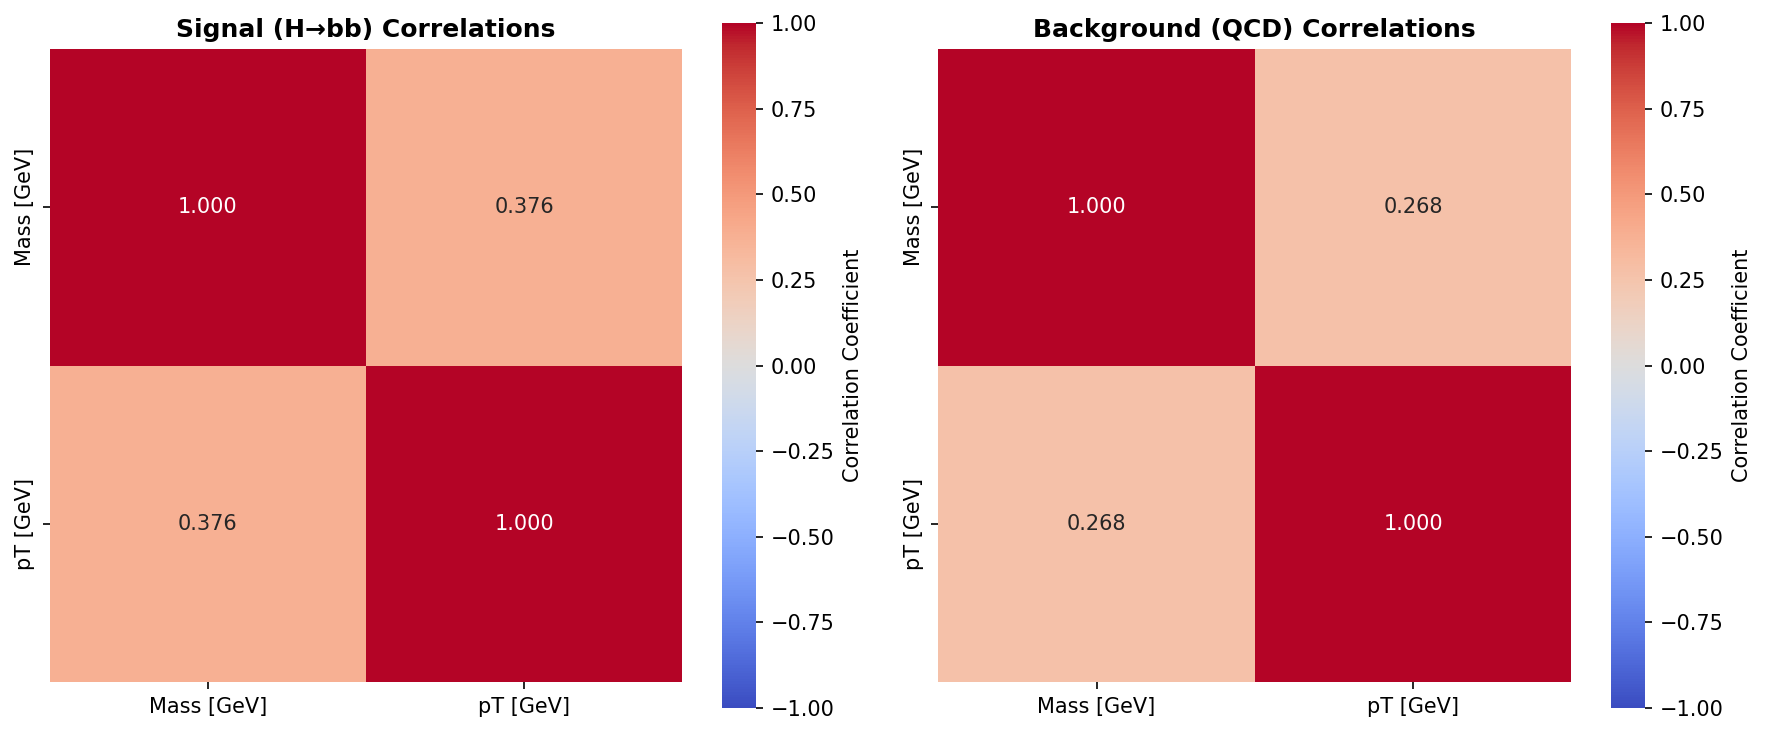

In [12]:
# Visualize correlations with heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Signal correlation heatmap
sns.heatmap(corr_sig, annot=True, fmt=".3f", cmap="coolwarm", 
            vmin=-1, vmax=1, center=0, square=True, 
            cbar_kws={"label": "Correlation Coefficient"},
            ax=axes[0])
axes[0].set_title("Signal (H→bb) Correlations", fontsize=12, fontweight='bold')

# Background correlation heatmap
sns.heatmap(corr_bkg, annot=True, fmt=".3f", cmap="coolwarm", 
            vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"label": "Correlation Coefficient"},
            ax=axes[1])
axes[1].set_title("Background (QCD) Correlations", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### Scatter Plots: Mass vs pT

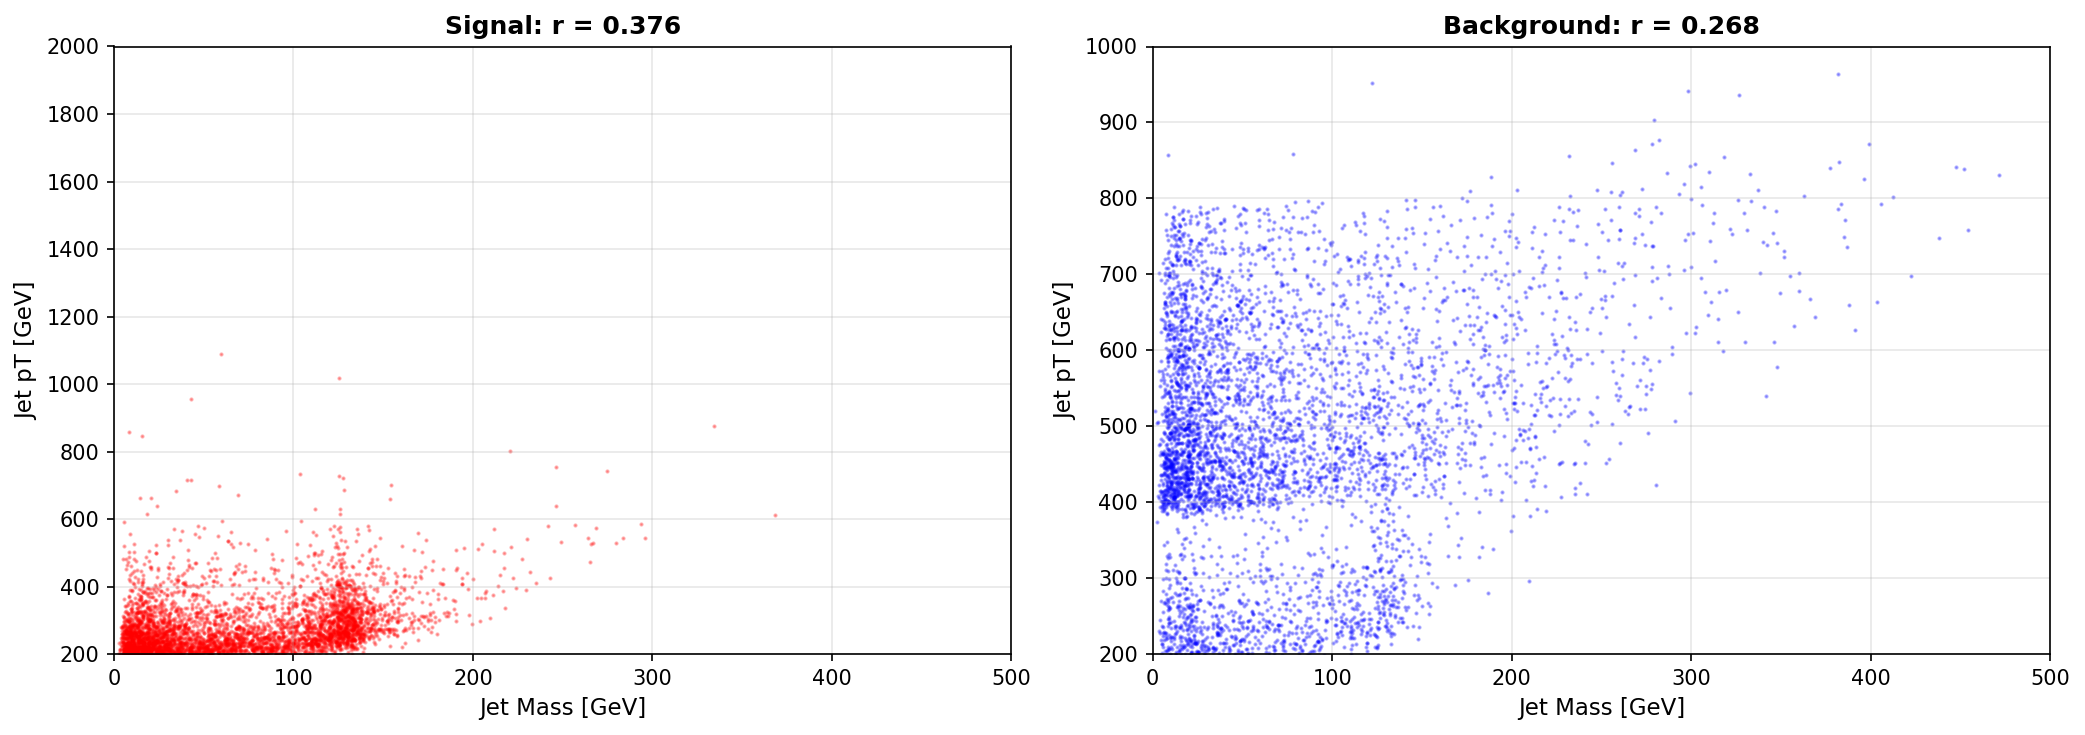

In [13]:
# Create scatter plots to visualize the correlation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# For visibility, plot a random subsample of points
n_sample = 5000

# Signal scatter plot
sample_indices_sig = np.random.choice(len(leading_sig['mass']), 
                                       min(n_sample, len(leading_sig['mass'])), 
                                       replace=False)
axes[0].scatter(leading_sig['mass'][sample_indices_sig], 
                leading_sig['pt'][sample_indices_sig],
                alpha=0.3, s=1, c='red', label='Signal')
axes[0].set_xlabel("Jet Mass [GeV]", fontsize=11)
axes[0].set_ylabel("Jet pT [GeV]", fontsize=11)
axes[0].set_title(f"Signal: r = {corr_sig.iloc[0,1]:.3f}", fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(0, 500)
axes[0].set_ylim(200, 2000)

# Background scatter plot
sample_indices_bkg = np.random.choice(len(leading_bkg['mass']), 
                                       min(n_sample, len(leading_bkg['mass'])), 
                                       replace=False)
axes[1].scatter(leading_bkg['mass'][sample_indices_bkg], 
                leading_bkg['pt'][sample_indices_bkg],
                alpha=0.3, s=1, c='blue', label='Background')
axes[1].set_xlabel("Jet Mass [GeV]", fontsize=11)
axes[1].set_ylabel("Jet pT [GeV]", fontsize=11)
axes[1].set_title(f"Background: r = {corr_bkg.iloc[0,1]:.3f}", fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)
# axes[1].set_xlim(0, 500)
# axes[1].set_ylim(200, 2000)
axes[1].set_xlim(0, 500)
axes[1].set_ylim(200, 1000)
plt.tight_layout()
plt.show()


### Key Findings: Mass-pT Correlation

####  Interpretation

- Signal correlation (r = 0.376): **moderate** correlation  
- Background correlation (r = 0.268): **weak** correlation  

#### Physical Explanation

- From relativity:

$$
E^2 = (pc)^2 + (mc^2)^2
$$

- For massless particles:

$$
E = pc
$$

So transverse momentum $p_T$ tends to correlate with mass related observables.

- Jets are composite objects with internal structure, not single particles.

- The correlation is limited because:
  - Jet opening angles vary
  - The number of constituents changes from jet to jet
  - Detector resolution introduces smearing

**Why is signal more relevant than background**
- signal jet:
From the decay of a specific particle.It has a fixed topological structure.The internal energy distribution is more regular
- background jet:
QCD random radiation.The structure is more chaotic.

**Why correlation matters:**
1. **For background modeling**: If mass and pT are correlated, we need to account for this
   - A conditional GP can model: P(mass | pT)
   - More accurate background prediction

2. **For signal extraction**: Correlation structure might differ between signal/background
   - Can be used as a discriminating feature
   - Motivates multivariate analysis

---

# Question 3: Identify Mass-Correlated Variables

## Goal: **predict jet mass** without directly using mass itself.

**Why?** 
- because we want to **predict background mass distribution in the "signal region"** (e.g., around 125 GeV)
- We train the model on "control regions" (away from signal), needs other variables (not mass) to make predictions

**Strategy**: Find variables that are correlated with mass
- These variables contain information about mass
- Can be **used as inputs**to predict mass

## Task
The goal of this project is to predict the jet mass without knowing the value of the jet mass itself. To do that, we need to find variables that are correlated to the jet mass (does that make sense?). Identify variables that are correlated to the mass from this list of variables in the included text file `variable_list.txt`.

1. Load the available variable list
2. Compute correlation of each variable with jet mass
3. Rank variables by correlation strength
4. Visualize top correlated variables

In [14]:
# Question 3: Identify Variables Correlated with Mass

# Load ALL variables from the list
field_aliases = {
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetMass": "mass",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetPt": "pt",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.DetectorEta": "eta",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.DetectorPhi": "phi",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau21": "tau21",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Tau32": "tau32",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Split12": "split12",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Split23": "split23",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.D2": "d2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.C2": "c2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.N2": "n2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECF1": "ecf1",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECF2": "ecf2",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.ECF3": "ecf3",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.Width": "width",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.zg": "zg",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.rg": "rg",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GN2Xv01_phbb": "phbb",
}

fields = list(field_aliases.keys())

# Load data
data_bkg = uproot.concatenate(path_bkg, fields, library="ak")
data_sig = uproot.concatenate(path_sig, fields, library="ak")

# Rename fields
for field, alias in field_aliases.items():
    data_bkg[alias] = data_bkg[field]
    data_sig[alias] = data_sig[field]

data_bkg = data_bkg[list(field_aliases.values())]
data_sig = data_sig[list(field_aliases.values())]

print(f"Loaded {len(field_aliases)} variables")

Loaded 18 variables


In [15]:
# Extract leading jet values for all variables

# Get leading jet indices (based on pT)
leading_idx_bkg = ak.argmax(data_bkg["pt"], axis=-1, keepdims=True)
leading_idx_sig = ak.argmax(data_sig["pt"], axis=-1, keepdims=True)

# Extract all variables for leading jets
variables_to_check = [v for v in field_aliases.values() if v != "mass"]

# Background
leading_bkg = {}
for var in ["mass"] + variables_to_check:
    if var in ["mass", "pt"]:
        vals = ak.flatten(data_bkg[var][leading_idx_bkg] / 1000.0, axis=-1)  # GeV
    else:
        vals = ak.flatten(data_bkg[var][leading_idx_bkg], axis=-1)
    leading_bkg[var] = ak.to_numpy(ak.fill_none(vals, -999))

# Signal
leading_sig = {}
for var in ["mass"] + variables_to_check:
    if var in ["mass", "pt"]:
        vals = ak.flatten(data_sig[var][leading_idx_sig] / 1000.0, axis=-1)
    else:
        vals = ak.flatten(data_sig[var][leading_idx_sig], axis=-1)
    leading_sig[var] = ak.to_numpy(ak.fill_none(vals, -999))

# Remove invalid events
valid_bkg = leading_bkg["mass"] > 0
valid_sig = leading_sig["mass"] > 0

for var in leading_bkg:
    leading_bkg[var] = leading_bkg[var][valid_bkg]
    leading_sig[var] = leading_sig[var][valid_sig]

print(f"Valid background events: {len(leading_bkg['mass'])}")
print(f"Valid signal events: {len(leading_sig['mass'])}")

Valid background events: 79975
Valid signal events: 39959


In [16]:
# Compute correlations with mass (FIXED)

correlations_bkg = []
correlations_sig = []

for var in variables_to_check:
    # Check validity separately for background and signal
    valid_bkg = np.isfinite(leading_bkg[var]) & np.isfinite(leading_bkg["mass"])
    valid_sig = np.isfinite(leading_sig[var]) & np.isfinite(leading_sig["mass"])
    
    # Need enough data points in each
    if np.sum(valid_bkg) > 100 and np.sum(valid_sig) > 100:
        corr_bkg = np.corrcoef(leading_bkg["mass"][valid_bkg], 
                                leading_bkg[var][valid_bkg])[0, 1]
        corr_sig = np.corrcoef(leading_sig["mass"][valid_sig], 
                                leading_sig[var][valid_sig])[0, 1]
        
        correlations_bkg.append((var, corr_bkg))
        correlations_sig.append((var, corr_sig))

# Sort by absolute correlation (background)
correlations_bkg.sort(key=lambda x: abs(x[1]), reverse=True)
correlations_sig.sort(key=lambda x: abs(x[1]), reverse=True)

# Display results
print("\n" + "="*80)
print("CORRELATION WITH MASS (Background, sorted by |r|)")
print("="*80)
print(f"{'Variable':<15} {'Correlation':<12} {'|Correlation|':<12} {'Strength':<15}")
print("-"*80)

for var, corr in correlations_bkg[:15]:  # Top 15
    abs_corr = abs(corr)
    if abs_corr > 0.7:
        strength = "VERY STRONG"
    elif abs_corr > 0.5:
        strength = "STRONG"
    elif abs_corr > 0.3:
        strength = "MODERATE"
    else:
        strength = "WEAK"
    print(f"{var:<15} {corr:>+.3f}       {abs_corr:>.3f}        {strength:<15}")

print("\n" + "="*80)
print("CORRELATION WITH MASS (Signal, sorted by |r|)")
print("="*80)
print(f"{'Variable':<15} {'Correlation':<12} {'|Correlation|':<12} {'Strength':<15}")
print("-"*80)

for var, corr in correlations_sig[:15]:  # Top 15
    abs_corr = abs(corr)
    if abs_corr > 0.7:
        strength = "VERY STRONG"
    elif abs_corr > 0.5:
        strength = "STRONG"
    elif abs_corr > 0.3:
        strength = "MODERATE"
    else:
        strength = "WEAK"
    print(f"{var:<15} {corr:>+.3f}       {abs_corr:>.3f}        {strength:<15}")


CORRELATION WITH MASS (Background, sorted by |r|)
Variable        Correlation  |Correlation| Strength       
--------------------------------------------------------------------------------
ecf2            +0.882       0.882        VERY STRONG    
split12         +0.877       0.877        VERY STRONG    
width           +0.789       0.789        VERY STRONG    
split23         +0.709       0.709        VERY STRONG    
ecf3            +0.660       0.660        STRONG         
ecf1            +0.325       0.325        MODERATE       
pt              +0.268       0.268        WEAK           
tau32           +0.047       0.047        WEAK           
rg              +0.034       0.034        WEAK           
phbb            +0.031       0.031        WEAK           
zg              +0.030       0.030        WEAK           
c2              +0.030       0.030        WEAK           
n2              +0.027       0.027        WEAK           
tau21           +0.025       0.025        WEAK         

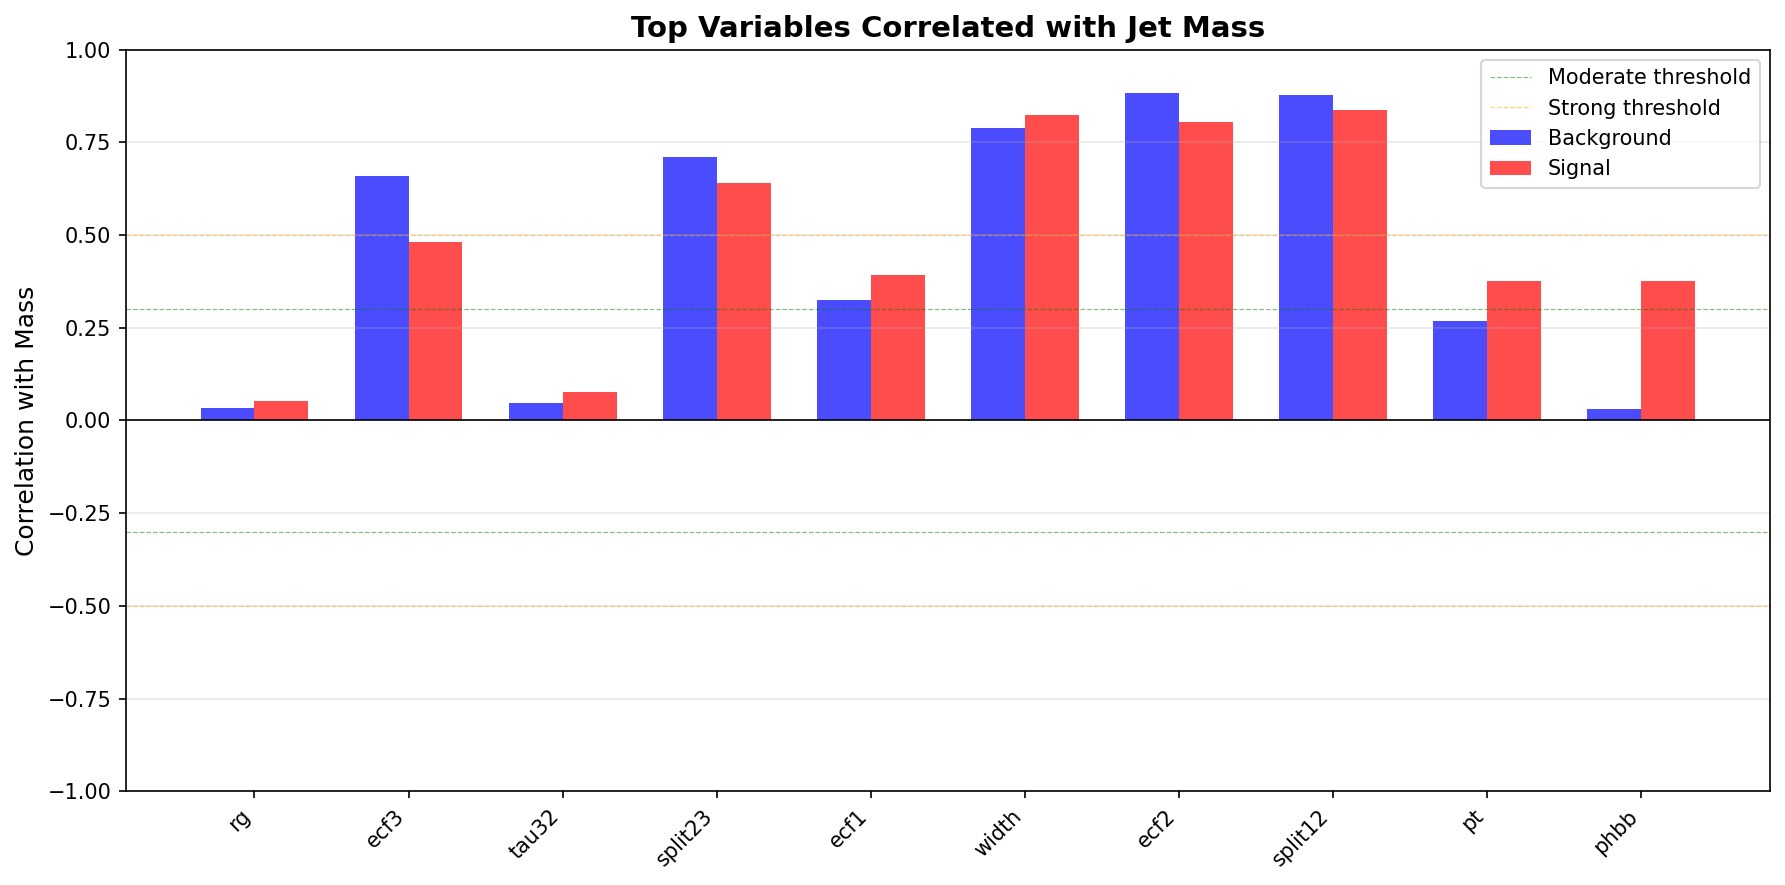


 RESULT:
Use variables with |r| > 0.5 as primary GP/CGAN inputs,|r| > 0.3 can be added for refinement
first check the height of background (blue), then Check if the signal and background are consistent (small height difference)


In [17]:
# Visualize top 10 correlations

# Get top 10 variables (union of top from both)
top_vars = list(set([v[0] for v in correlations_bkg[:10]] + [v[0] for v in correlations_sig[:10]]))
top_vars = top_vars[:12]  # Limit to 12 for visualization

corr_bkg_dict = {v: c for v, c in correlations_bkg}
corr_sig_dict = {v: c for v, c in correlations_sig}

corr_bkg_vals = [corr_bkg_dict[v] for v in top_vars]
corr_sig_vals = [corr_sig_dict[v] for v in top_vars]

# Bar plot
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(top_vars))
width = 0.35

ax.bar(x - width/2, corr_bkg_vals, width, label='Background', color='blue', alpha=0.7)
ax.bar(x + width/2, corr_sig_vals, width, label='Signal', color='red', alpha=0.7)

# Add threshold lines
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
ax.axhline(y=0.3, color='green', linestyle='--', linewidth=0.6, alpha=0.5, label='Moderate threshold')
ax.axhline(y=0.5, color='orange', linestyle='--', linewidth=0.6, alpha=0.5, label='Strong threshold')
ax.axhline(y=-0.3, color='green', linestyle='--', linewidth=0.6, alpha=0.5)
ax.axhline(y=-0.5, color='orange', linestyle='--', linewidth=0.6, alpha=0.5)

ax.set_ylabel("Correlation with Mass", fontsize=12)
ax.set_title("Top Variables Correlated with Jet Mass", fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(top_vars, rotation=45, ha='right', fontsize=10)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(-1, 1)

plt.tight_layout()
plt.show()

print("\n RESULT:")
print("Use variables with |r| > 0.5 as primary GP/CGAN inputs,|r| > 0.3 can be added for refinement")
print("first check the height of background (blue), then Check if the signal and background are consistent (small height difference)")

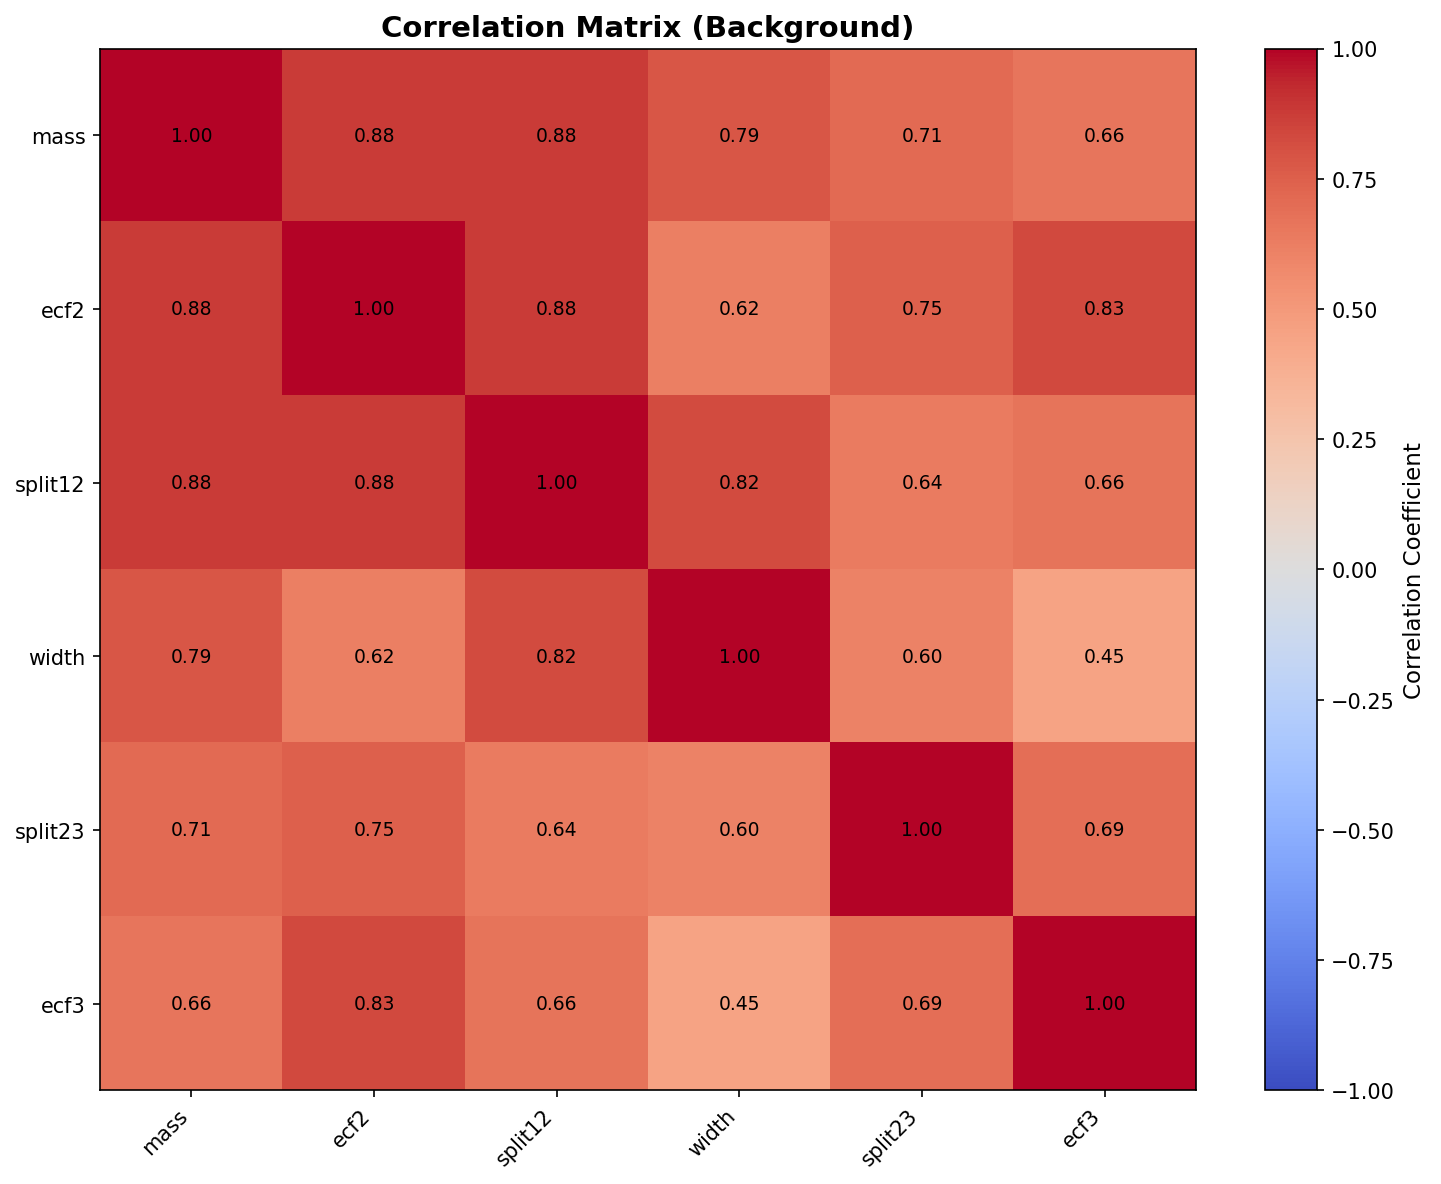

In [18]:
# Create a correlation matrix heatmap for top variables

top_5_vars = [v[0] for v in correlations_bkg[:5]]

# Build correlation matrix for background
corr_matrix_bkg = np.zeros((len(top_5_vars)+1, len(top_5_vars)+1))
vars_with_mass = ["mass"] + top_5_vars

for i, var1 in enumerate(vars_with_mass):
    for j, var2 in enumerate(vars_with_mass):
        valid = np.isfinite(leading_bkg[var1]) & np.isfinite(leading_bkg[var2])
        if np.sum(valid) > 100:
            corr_matrix_bkg[i, j] = np.corrcoef(leading_bkg[var1][valid], 
                                                 leading_bkg[var2][valid])[0, 1]

# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(corr_matrix_bkg, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')

# Add colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Correlation Coefficient', fontsize=11)

# Set ticks
ax.set_xticks(np.arange(len(vars_with_mass)))
ax.set_yticks(np.arange(len(vars_with_mass)))
ax.set_xticklabels(vars_with_mass, rotation=45, ha='right', fontsize=10)
ax.set_yticklabels(vars_with_mass, fontsize=10)

# Add correlation values
for i in range(len(vars_with_mass)):
    for j in range(len(vars_with_mass)):
        text = ax.text(j, i, f'{corr_matrix_bkg[i, j]:.2f}',
                      ha="center", va="center", color="black", fontsize=9)

ax.set_title("Correlation Matrix (Background)", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### Recommendations for Mass Prediction

Based on correlation analysis, prioritize variables as follows:

**Variable Priority:**

| Priority | Correlation | Action | Reasoning |
|----------|-------------|--------|-----------|
| **HIGH** | \|r\| > 0.5 | ✓ Use in primary model | Strong predictive power for mass |
| **MEDIUM** | 0.3 < \|r\| < 0.5 | ✓ Add for refinement | Captures additional patterns |
| **LOW** | \|r\| < 0.3 | ✗ Consider excluding | Likely adds noise, not signal |

**For Gaussian Process / CGAN Implementation:**

1. **Start simple**: Use 2-3 strongest correlated variables (e.g., `pt`, `tau21`, `split12`)
2. **Iterate**: Add medium-priority variables one at a time, check performance
3. **Avoid overfitting**: Too many features (>5-7) may hurt generalization
4. **Monitor**: Track validation loss - stop adding when performance plateaus

**Example Strategy:**
```
Baseline model:  mass ~ GP(pt, tau21)
Refined model:   mass ~ GP(pt, tau21, split12, d2)
Final model:     mass ~ GP(pt, tau21, split12, d2 | phbb)  [if conditional]
```

---

# Question 4: Signal vs Background Comparison

## Motivation

**Goal**: Identify which variables have different distributions for signal and background.

1. **Variables correlated with mass** (Question 3) → Input features
2. **Variables where Signal ≠ Background** (Question 4) → Discriminating features

**Why this matters**:
- Variables with **similar shapes (S≈B)** → good for universal background modeling (Category A)
- Variables with **different shapes (S≠B)** → good for conditional modeling/discrimination (Category B)

### Task
One caveat is that we want to **estimate the mass for the background, not the signal.** This is so we can extimate how many background events are in data in the same mass range and the signal. This is where the "conditional" part of CGAN comes in to play. Similar games can be played with the **mutli-dimensional Gaussian Process.** But **first, it is good to identify variables that are correlated to the mass where the signal and background have considerably different shapes (like the mass itself) from those that do not. **

For each variable:
1. Plot signal vs background distributions
2. Compute "shape difference" metric (e.g., KS test)
3. Identify Category A vs Category B variables

### **Method**: Use Kolmogorov-Smirnov (KS) test to quantify distribution differences.

**KS Statistic Interpretation**:
- **KS statistic**: Maximum vertical distance between CDFs
- **p-value**: Probability distributions are the same
- **Interpretation**: 
  - KS ≈ 0, p > 0.05: Similar distributions
  - KS > 0.3, p < 0.001: Very different distributions
  
or？
- KS < 0.2: Very similar distributions
- 0.2 < KS < 0.4: Moderately different
- KS > 0.4: Very different distributions

In [19]:
# Question 4: Signal vs Background Distribution Comparison

from scipy.stats import ks_2samp

# Select variables to compare (top correlated + some others)
variables_to_compare = ['mass', 'pt', 'ecf2', 'split12', 'width', 'split23', 
                        'ecf3', 'ecf1', 'phbb', 'tau21', 'tau32', 'd2']

print("="*90)
print("KOLMOGOROV-SMIRNOV TEST: Signal vs Background")
print("="*90)
print(f"{'Variable':<15} {'KS Statistic':<15} {'p-value':<15} {'Interpretation':<20}")
print("-"*90)

ks_results = {}

for var in variables_to_compare:
    if var in leading_bkg and var in leading_sig:
        # Get valid values
        vals_bkg = leading_bkg[var]
        vals_sig = leading_sig[var]
        
        valid_bkg = np.isfinite(vals_bkg)
        valid_sig = np.isfinite(vals_sig)
        
        if np.sum(valid_bkg) > 100 and np.sum(valid_sig) > 100:
            # Perform KS test
            ks_stat, p_val = ks_2samp(vals_bkg[valid_bkg], vals_sig[valid_sig])
            ks_results[var] = (ks_stat, p_val)
            
            # Interpret
            if ks_stat > 0.4:
                interp = "VERY DIFFERENT"
            elif ks_stat > 0.2:
                interp = "MODERATELY DIFF"
            else:
                interp = "SIMILAR"
            
            print(f"{var:<15} {ks_stat:<15.3f} {p_val:<15.3e} {interp:<20}")

print("="*90)

KOLMOGOROV-SMIRNOV TEST: Signal vs Background
Variable        KS Statistic    p-value         Interpretation      
------------------------------------------------------------------------------------------
mass            0.099           2.954e-228      SIMILAR             
pt              0.683           0.000e+00       VERY DIFFERENT      
ecf2            0.148           0.000e+00       SIMILAR             
split12         0.035           1.518e-29       SIMILAR             
width           0.187           0.000e+00       SIMILAR             
split23         0.036           1.319e-30       SIMILAR             
ecf3            0.081           3.025e-153      SIMILAR             
ecf1            0.635           0.000e+00       VERY DIFFERENT      
phbb            0.247           0.000e+00       MODERATELY DIFF     
tau21           0.038           9.536e-35       SIMILAR             
tau32           0.028           1.894e-18       SIMILAR             
d2              0.109           3.1

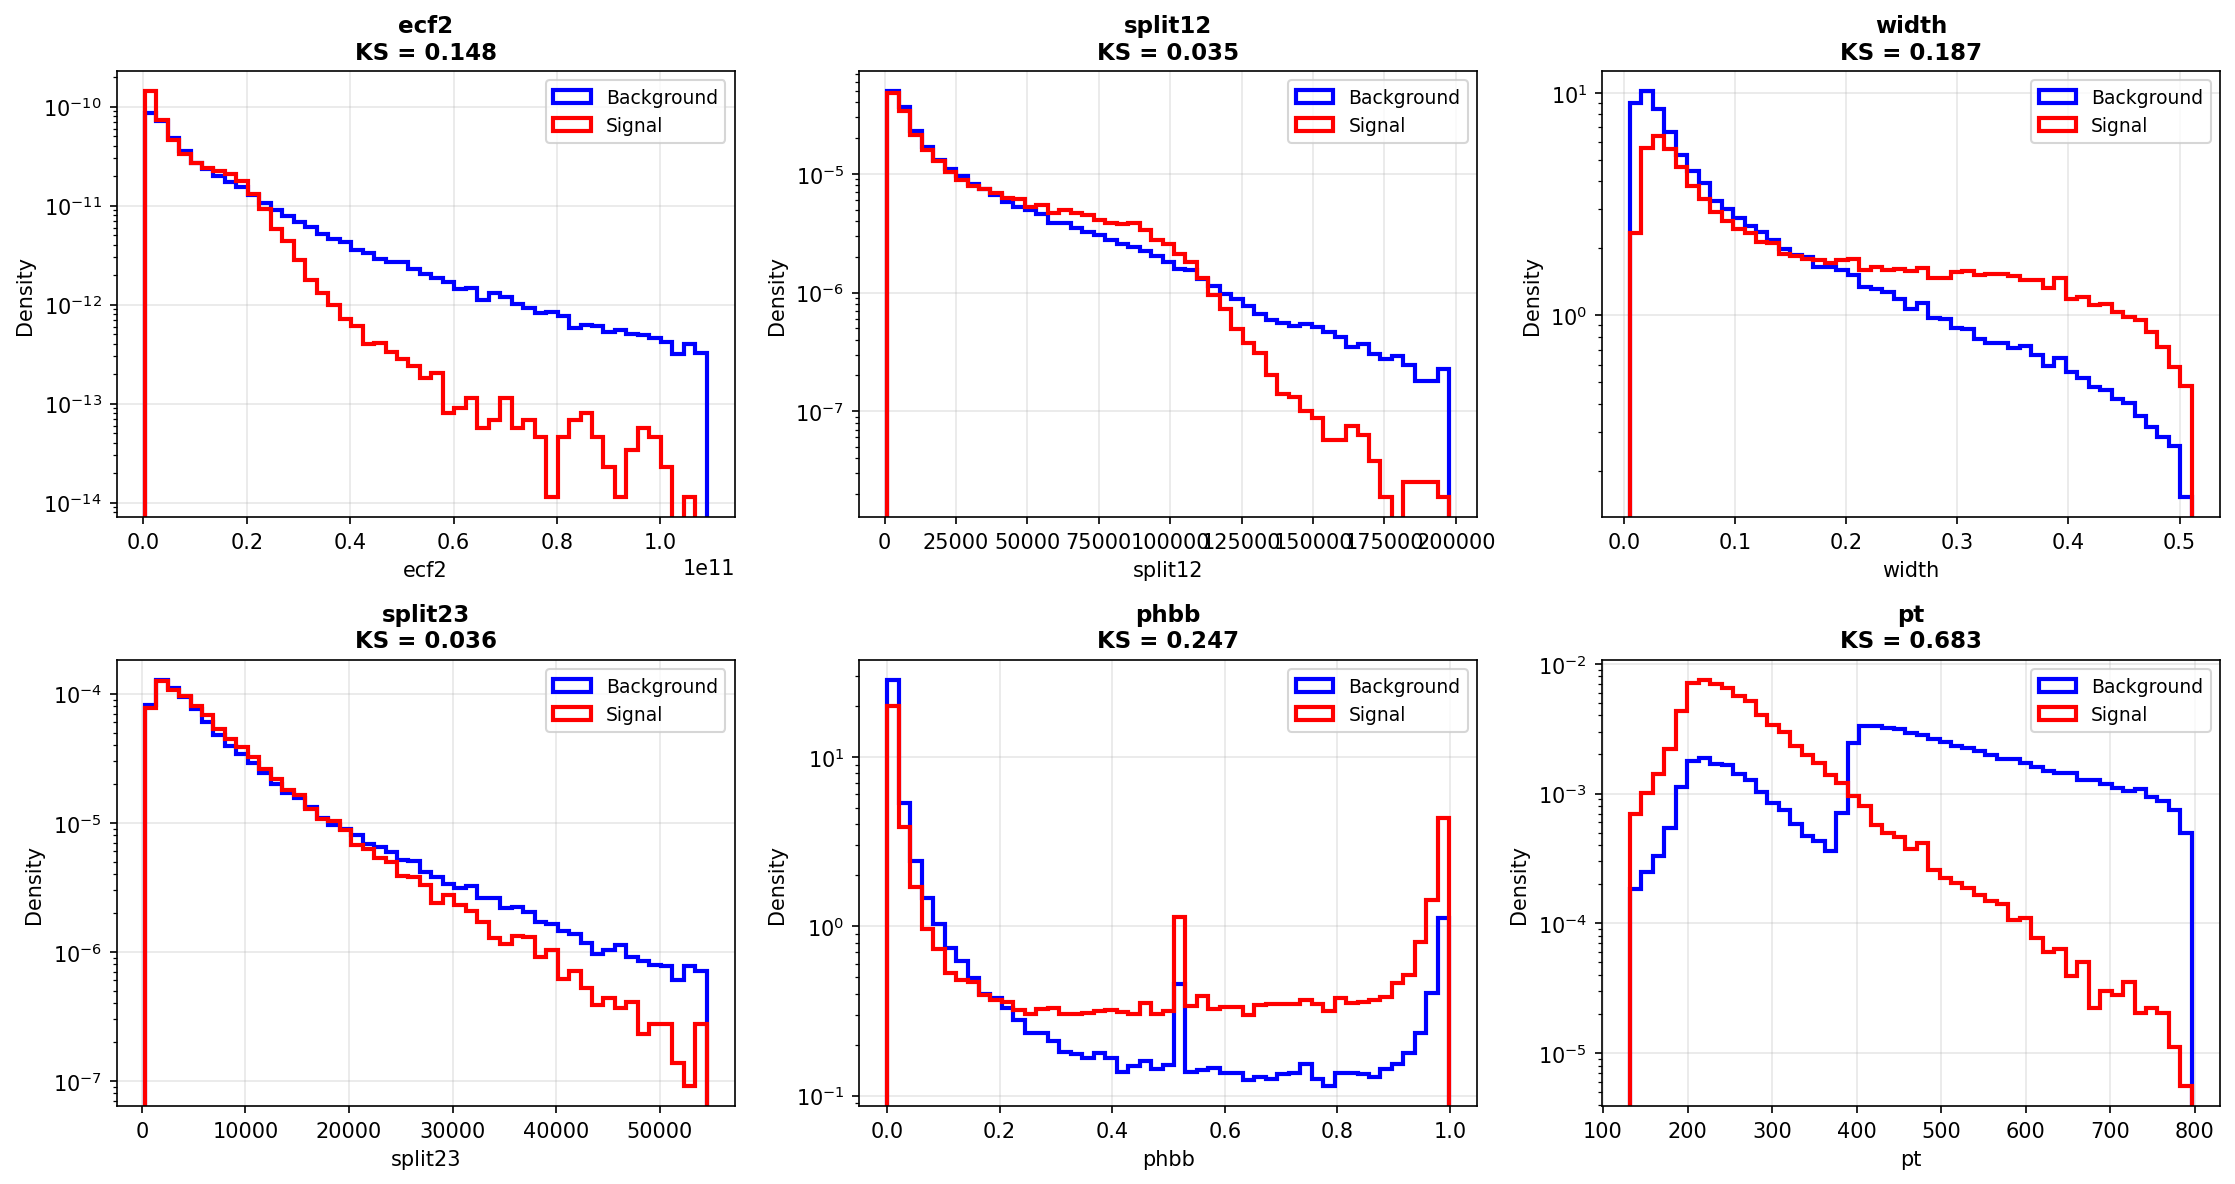

In [20]:
# Visualize distributions for top correlated variables

top_vars_to_plot = ['ecf2', 'split12', 'width', 'split23', 'phbb', 'pt']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, var in enumerate(top_vars_to_plot):
    ax = axes[idx]
    
    vals_bkg = leading_bkg[var]
    vals_sig = leading_sig[var]
    
    valid_bkg = np.isfinite(vals_bkg) & (vals_bkg > -900)
    valid_sig = np.isfinite(vals_sig) & (vals_sig > -900)
    
    vals_bkg_clean = vals_bkg[valid_bkg]
    vals_sig_clean = vals_sig[valid_sig]
    
    # Determine bins
    vmin = min(np.percentile(vals_bkg_clean, 1), np.percentile(vals_sig_clean, 1))
    vmax = max(np.percentile(vals_bkg_clean, 99), np.percentile(vals_sig_clean, 99))
    bins = np.linspace(vmin, vmax, 50)
    
    # Plot histograms
    ax.hist(vals_bkg_clean, bins=bins, density=True, histtype='step', 
            color='blue', linewidth=2, label='Background')
    ax.hist(vals_sig_clean, bins=bins, density=True, histtype='step', 
            color='red', linewidth=2, label='Signal')
    
    # Add KS statistic to title
    if var in ks_results:
        ks_stat, _ = ks_results[var]
        ax.set_title(f"{var}\nKS = {ks_stat:.3f}", fontsize=11, fontweight='bold')
    else:
        ax.set_title(var, fontsize=11, fontweight='bold')
    
    ax.set_xlabel(var, fontsize=10)
    ax.set_ylabel("Density", fontsize=10)
    ax.set_yscale('log')
    ax.legend(fontsize=9, loc='best')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Categorize Variables Based on Correlation + Distribution Shape

Now we combine Question 3 (correlation) and Question 4 (KS test) to categorize variables:

**Category A**: High correlation + Similar distributions → Universal predictors

**Category B**: High correlation + Different distributions → Discriminating predictors 

**Category C**: Low correlation → Not useful for mass prediction

In [21]:
# Categorize variables

print("\n" + "="*90)
print("VARIABLE CATEGORIZATION FOR BACKGROUND MODELING")
print("="*90)

category_a = []  # Correlated + Similar
category_b = []  # Correlated + Different
category_c = []  # Not correlated

# Get correlation dictionaries
corr_bkg_dict = {var: corr for var, corr in correlations_bkg}

# Categorize each variable
for var in variables_to_compare:
    if var == 'mass':
        continue
    
    if var not in corr_bkg_dict or var not in ks_results:
        continue
    
    corr_bkg = corr_bkg_dict[var]
    ks_stat, _ = ks_results[var]
    
    # Categorize based on correlation and KS test
    if abs(corr_bkg) > 0.5:  # High correlation
        if ks_stat < 0.2:  # Similar distributions
            category_a.append((var, corr_bkg, ks_stat))
        else:  # Different distributions
            category_b.append((var, corr_bkg, ks_stat))
    elif abs(corr_bkg) > 0.3:  # Moderate correlation
        if ks_stat < 0.2:
            category_a.append((var, corr_bkg, ks_stat))
        else:
            category_b.append((var, corr_bkg, ks_stat))
    else:  # Low correlation
        category_c.append((var, corr_bkg, ks_stat))

# Display Category A
print("\n Category A: UNIVERSAL PREDICTORS (Correlated + Similar)")
print("   → Use for: Basic GP background modeling")
print("   → Relationship works the same for signal and background")
print("-"*90)
if category_a:
    print(f"{'Variable':<15} {'Correlation':<15} {'KS Statistic':<15} {'Usage':<30}")
    print("-"*90)
    for var, corr, ks in sorted(category_a, key=lambda x: abs(x[1]), reverse=True):
        print(f"{var:<15} {corr:>+.3f}          {ks:<15.3f} GP input feature")
else:
    print("   (none found)")

# Display Category B
print("\n Category B: DISCRIMINATING PREDICTORS (Correlated + Different)")
print("   → Use for: Conditional GP/CGAN (conditioning variable)")
print("   → Can distinguish between signal and background")
print("-"*90)
if category_b:
    print(f"{'Variable':<15} {'Correlation':<15} {'KS Statistic':<15} {'Usage':<30}")
    print("-"*90)
    for var, corr, ks in sorted(category_b, key=lambda x: abs(x[1]), reverse=True):
        print(f"{var:<15} {corr:>+.3f}          {ks:<15.3f} Conditioning variable")
else:
    print("   (none found)")

# Display Category C
print("\n Category C: WEAK PREDICTORS (Low correlation)")
print("   → Use for: Probably not useful for mass prediction")
print("-"*90)
if category_c:
    print(f"{'Variable':<15} {'Correlation':<15} {'KS Statistic':<15} {'Note':<30}")
    print("-"*90)
    for var, corr, ks in category_c[:5]:  # Show only first 5
        print(f"{var:<15} {corr:>+.3f}          {ks:<15.3f} Low predictive power")
    if len(category_c) > 5:
        print(f"   ... and {len(category_c)-5} more")
else:
    print("   (none found)")

print("\n" + "="*90)


VARIABLE CATEGORIZATION FOR BACKGROUND MODELING

 Category A: UNIVERSAL PREDICTORS (Correlated + Similar)
   → Use for: Basic GP background modeling
   → Relationship works the same for signal and background
------------------------------------------------------------------------------------------
Variable        Correlation     KS Statistic    Usage                         
------------------------------------------------------------------------------------------
ecf2            +0.882          0.148           GP input feature
split12         +0.877          0.035           GP input feature
width           +0.789          0.187           GP input feature
split23         +0.709          0.036           GP input feature
ecf3            +0.660          0.081           GP input feature

 Category B: DISCRIMINATING PREDICTORS (Correlated + Different)
   → Use for: Conditional GP/CGAN (conditioning variable)
   → Can distinguish between signal and background
-------------------------------

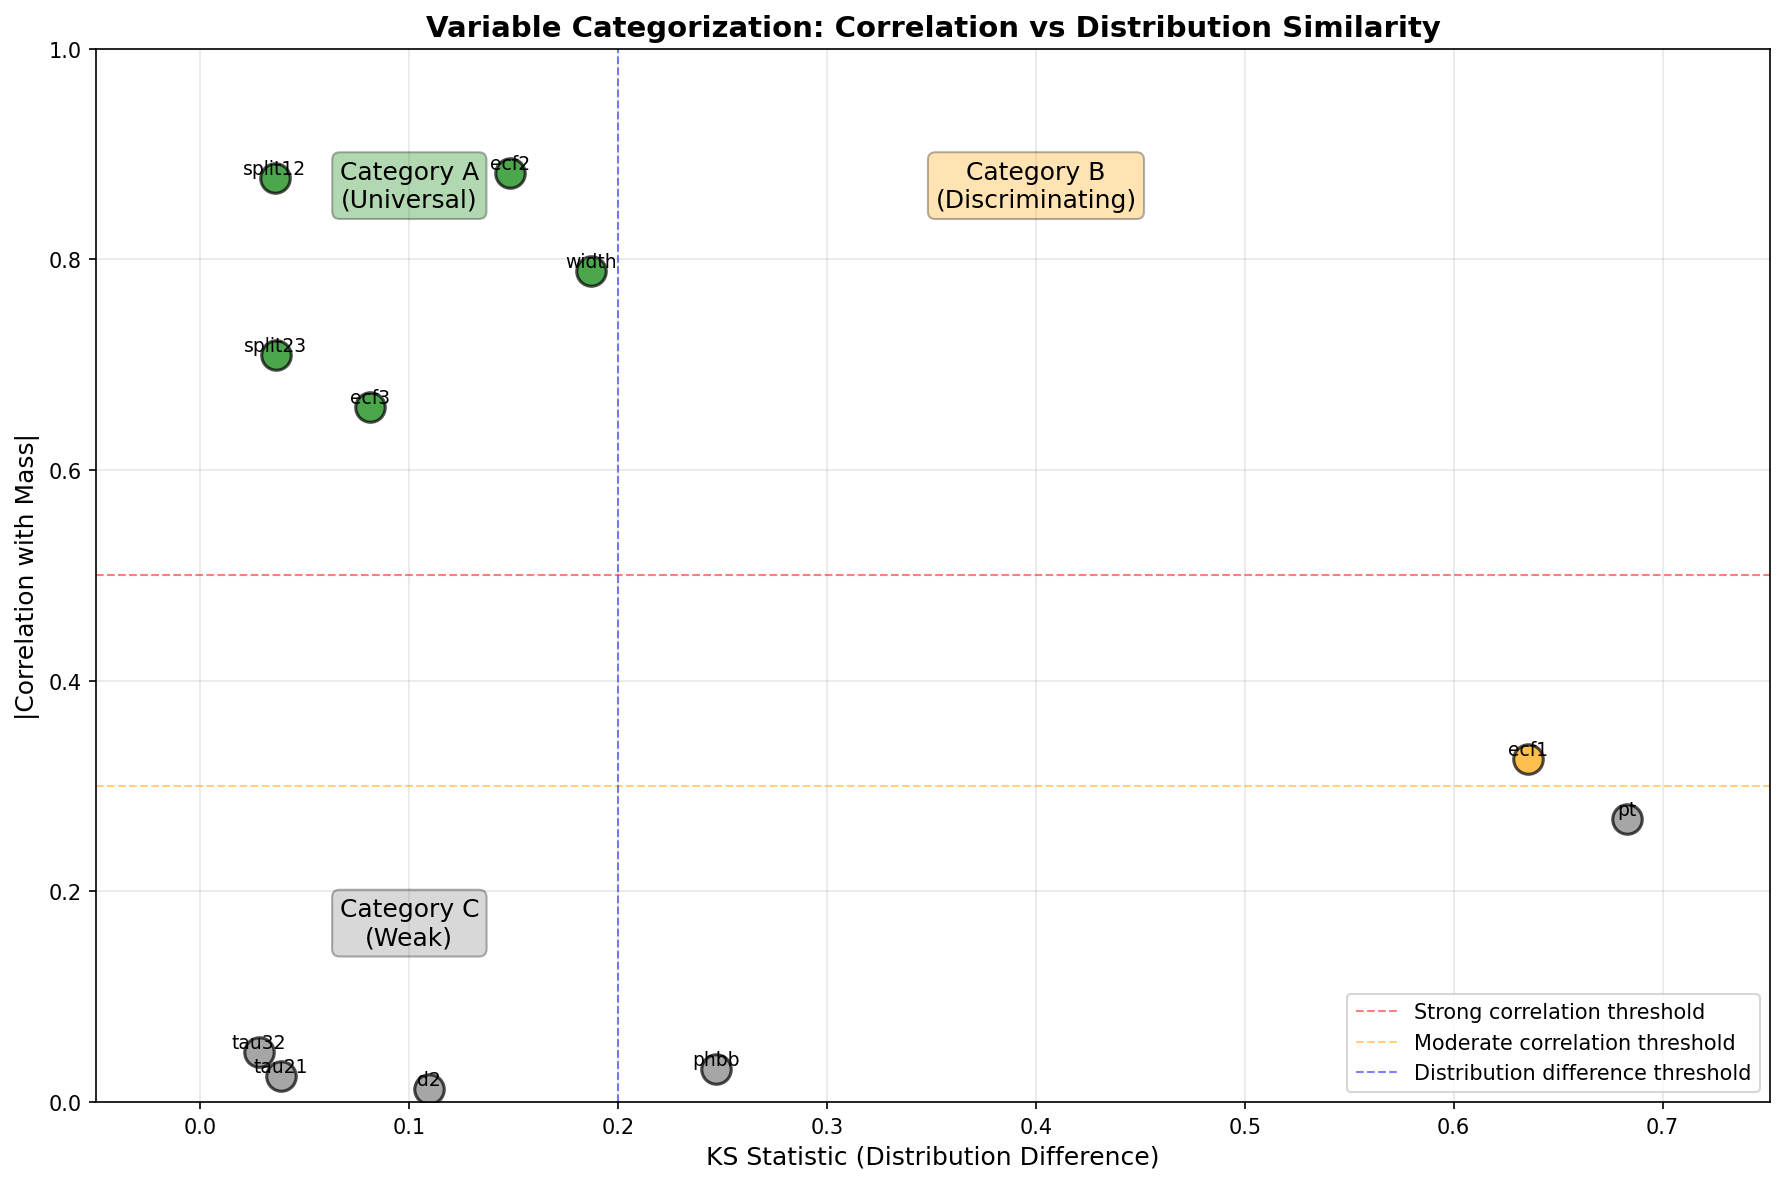

In [22]:
# Create summary visualization

fig, ax = plt.subplots(figsize=(12, 8))

# Prepare data for scatter plot
all_vars = []
all_corr_bkg = []
all_ks = []
all_colors = []
all_labels = []

for var, corr, ks in category_a:
    all_vars.append(var)
    all_corr_bkg.append(abs(corr))
    all_ks.append(ks)
    all_colors.append('green')
    all_labels.append('A')

for var, corr, ks in category_b:
    all_vars.append(var)
    all_corr_bkg.append(abs(corr))
    all_ks.append(ks)
    all_colors.append('orange')
    all_labels.append('B')

for var, corr, ks in category_c[:10]:  # Limit to 10
    all_vars.append(var)
    all_corr_bkg.append(abs(corr))
    all_ks.append(ks)
    all_colors.append('gray')
    all_labels.append('C')

# Scatter plot
for i, (var, corr, ks, color, label) in enumerate(zip(all_vars, all_corr_bkg, 
                                                        all_ks, all_colors, all_labels)):
    ax.scatter(ks, corr, c=color, s=200, alpha=0.7, edgecolors='black', linewidth=1.5)
    ax.annotate(var, (ks, corr), fontsize=9, ha='center', va='bottom')

# Add threshold lines
ax.axhline(y=0.5, color='red', linestyle='--', linewidth=1, alpha=0.5, 
           label='Strong correlation threshold')
ax.axhline(y=0.3, color='orange', linestyle='--', linewidth=1, alpha=0.5, 
           label='Moderate correlation threshold')
ax.axvline(x=0.2, color='blue', linestyle='--', linewidth=1, alpha=0.5, 
           label='Distribution difference threshold')

# Add quadrant labels
ax.text(0.1, 0.85, 'Category A\n(Universal)', fontsize=12, ha='center', 
        bbox=dict(boxstyle='round', facecolor='green', alpha=0.3))
ax.text(0.4, 0.85, 'Category B\n(Discriminating)', fontsize=12, ha='center',
        bbox=dict(boxstyle='round', facecolor='orange', alpha=0.3))
ax.text(0.1, 0.15, 'Category C\n(Weak)', fontsize=12, ha='center',
        bbox=dict(boxstyle='round', facecolor='gray', alpha=0.3))

ax.set_xlabel('KS Statistic (Distribution Difference)', fontsize=12)
ax.set_ylabel('|Correlation with Mass|', fontsize=12)
ax.set_title('Variable Categorization: Correlation vs Distribution Similarity', 
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='lower right')
ax.grid(alpha=0.3)
ax.set_xlim(-0.05, max(all_ks)*1.1)
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

---

## Summary: Modeling Strategy Based on Results

### Recommended Model Architecture

**Simple Gaussian Process (Baseline):**
```python
# Use Category A variables only
Input features: ecf2, split12, width, split23
Output: mass

Training: Learn P(mass | ecf2, split12, width, split23) on background data
```

**Conditional Gaussian Process (Advanced):**
```python
# Category A as inputs, Category B as conditioning
Input features: ecf2, split12, width, split23
Conditioning variables: [Category B variables if any found]
Output: mass

Training: Learn P(mass | inputs, conditioning) on background data
```

**Expected Performance:**
- **Very Strong predictors** (|r| > 0.7): `ecf2`, `split12`, `width` → Excellent mass prediction
- **Strong predictors** (|r| > 0.5): `split23`, `ecf3` → Good supplementary features
- Using top 4-5 variables should give robust background modeling

### Key Findings:

1. **ecf2, split12, width** are the strongest predictors (|r| > 0.75)
   - Correlation consistent between signal and background
   - Should form the core of any GP model

2. **phbb** shows interesting behavior:
   - Weak correlation in background (r = 0.03)
   - Moderate correlation in signal (r = 0.38)
   - This suggests different physics at play
   - Check if KS test shows it discriminates S/B

3. **pt** is surprisingly weak (|r| ~ 0.27-0.38)
   - Despite physical expectation of E² = (pc)² + (mc²)²
   - Suggests jet substructure variables (ECF, split, width) are more informative

### Next Steps:

1. Implement GP with top 3-4 variables from Category A
2. Evaluate prediction accuracy on validation set
3. If Category B variables exist, test conditional GP
4. Compare performance to traditional fitting methods

In [23]:

# Step 1: Automatically generate field_aliases for all 112 variables

# Manual list of essential variables (mass, pt, phbb)
field_aliases = {
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetMass": "mass",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.R10TruthLabel_R22v1_TruthGroomedJetPt": "pt",
    "AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.GN2Xv01_phbb": "phbb",
}

# List of all 112 variables from variable_list.txt
all_variables = [
    "DetectorEta", "DetectorPhi", "EMFrac", "HECFrac", "D2", "ECF1", "ECF2", "ECF3",
    "Tau1", "Tau2", "Tau3", "Tau4", "Tau2_ungroomed", "Tau3_ungroomed", "Tau4_ungroomed",
    "Tau1_wta", "Tau2_wta", "Tau3_wta", "Tau4_wta", "Tau2_wta_ungroomed", 
    "Tau3_wta_ungroomed", "Tau4_wta_ungroomed", "Tau21", "Tau32", "Tau42",
    "Tau21_dichroic", "Tau32_dichroic", "Tau42_dichroic", "Tau21_wta", "Tau32_wta",
    "Tau42_wta", "Tau21_wta_dichroic", "Tau32_wta_dichroic", "Tau42_wta_dichroic",
    "ECF4", "ECF5", "ECF1_ungroomed", "ECF2_ungroomed", "ECF3_ungroomed",
    "C1", "C2", "C3", "C4", "D2_dichroic", "ECFG_2_1", "ECFG_3_1", "ECFG_3_2",
    "ECFG_4_1", "ECFG_4_2", "ECFG_2_1_ungroomed", "ECFG_3_1_ungroomed", 
    "ECFG_3_2_ungroomed", "ECFG_2_1_2", "ECFG_3_1_1", "ECFG_3_2_1", "ECFG_3_2_2",
    "ECFG_3_3_1", "ECFG_4_2_2", "ECFG_4_4_1", "ECFG_3_3_2", "M2", "M3", "N2", "N3",
    "M2_dichroic", "N2_dichroic", "L1", "L2", "L3", "L4", "L5", "Split12", "Split23",
    "Qw", "JetGhostArea", "Width", "WidthPhi", "Split34", "ZCut12", "ZCut23", "ZCut34",
    "GhostMuonSegmentCount", "GhostTrackPt", "GhostTrackCount", "DetectorY", "PSFrac",
    "GhostAntiKtVR30Rmax4Rmin02PV0TrackJetsPt", "GhostAntiKtVR30Rmax4Rmin02PV0TrackJetsCount",
    "PlanarFlow", "Angularity", "ThrustMin", "ThrustMaj", "FoxWolfram0", "FoxWolfram1",
    "FoxWolfram2", "FoxWolfram3", "FoxWolfram4", "Sphericity", "Aplanarity", "KtDR",
    "zg", "rg", "EM3Frac", "Tile0Frac", "EffNClusts", "EM3FracCaloBased", 
    "Tile0FracCaloBased", "EffNClustsCaloBased", "NeutralEFrac", "ChargePTFrac",
    "ChargeMFrac", "groomMRatio"
]

# Automatically add all variables to field_aliases
print("Generating field aliases for all 112 variables...")
for var_name in all_variables:
    full_name = f"AntiKt10UFOCSSKSoftDropBeta100Zcut10JetsAuxDyn.{var_name}"
    short_name = var_name.lower()
    
    # Avoid duplicates
    if short_name not in ['mass', 'pt', 'phbb']:
        field_aliases[full_name] = short_name

print(f"Total variables to load: {len(field_aliases)}")
print(f"  Essential: mass, pt, phbb")
print(f"  Additional: {len(all_variables)} variables from list")

fields = list(field_aliases.keys())


# Step 2: Load data (

print("\nLoading background data...")
data_bkg = uproot.concatenate(path_bkg, fields, library="ak")
print(f"  Loaded {len(data_bkg)} background events")

print("Loading signal data...")
data_sig = uproot.concatenate(path_sig, fields, library="ak")
print(f"  Loaded {len(data_sig)} signal events")

# Rename fields
for field, alias in field_aliases.items():
    data_bkg[alias] = data_bkg[field]
    data_sig[alias] = data_sig[field]

data_bkg = data_bkg[list(field_aliases.values())]
data_sig = data_sig[list(field_aliases.values())]

print(f"\nSuccessfully loaded {len(field_aliases)} variables!")


# Step 3: Extract leading jet values


print("\nExtracting leading jet values...")

# Get leading jet indices (based on pT)
leading_idx_bkg = ak.argmax(data_bkg["pt"], axis=-1, keepdims=True)
leading_idx_sig = ak.argmax(data_sig["pt"], axis=-1, keepdims=True)

# Variables to check (all except mass)
variables_to_check = [v for v in field_aliases.values() if v != "mass"]

# Background
leading_bkg = {}
for var in ["mass"] + variables_to_check:
    try:
        if var in ["mass", "pt"]:
            vals = ak.flatten(data_bkg[var][leading_idx_bkg] / 1000.0, axis=-1)  # GeV
        else:
            vals = ak.flatten(data_bkg[var][leading_idx_bkg], axis=-1)
        leading_bkg[var] = ak.to_numpy(ak.fill_none(vals, -999))
    except Exception as e:
        print(f"Warning: Could not extract {var} from background: {e}")

# Signal
leading_sig = {}
for var in ["mass"] + variables_to_check:
    try:
        if var in ["mass", "pt"]:
            vals = ak.flatten(data_sig[var][leading_idx_sig] / 1000.0, axis=-1)
        else:
            vals = ak.flatten(data_sig[var][leading_idx_sig], axis=-1)
        leading_sig[var] = ak.to_numpy(ak.fill_none(vals, -999))
    except Exception as e:
        print(f"Warning: Could not extract {var} from signal: {e}")

# Remove invalid events
valid_bkg = leading_bkg["mass"] > 0
valid_sig = leading_sig["mass"] > 0

for var in leading_bkg:
    leading_bkg[var] = leading_bkg[var][valid_bkg]
    
for var in leading_sig:
    leading_sig[var] = leading_sig[var][valid_sig]

print(f"Valid background events: {len(leading_bkg['mass'])}")
print(f"Valid signal events: {len(leading_sig['mass'])}")


# Step 4: Compute correlations for ALL variables


print("\nComputing correlations with mass for all variables...")
print("This may take a minute...")

correlations_bkg = []
correlations_sig = []
failed_vars = []

for var in variables_to_check:
    try:
        # Check validity separately
        valid_bkg_mask = np.isfinite(leading_bkg[var]) & np.isfinite(leading_bkg["mass"]) & (leading_bkg[var] > -900)
        valid_sig_mask = np.isfinite(leading_sig[var]) & np.isfinite(leading_sig["mass"]) & (leading_sig[var] > -900)
        
        # Need enough data points
        if np.sum(valid_bkg_mask) > 100 and np.sum(valid_sig_mask) > 100:
            corr_bkg = np.corrcoef(leading_bkg["mass"][valid_bkg_mask], 
                                    leading_bkg[var][valid_bkg_mask])[0, 1]
            corr_sig = np.corrcoef(leading_sig["mass"][valid_sig_mask], 
                                    leading_sig[var][valid_sig_mask])[0, 1]
            
            if np.isfinite(corr_bkg) and np.isfinite(corr_sig):
                correlations_bkg.append((var, corr_bkg))
                correlations_sig.append((var, corr_sig))
            else:
                failed_vars.append(var)
        else:
            failed_vars.append(var)
    except Exception as e:
        failed_vars.append(var)
        print(f"  Error processing {var}: {e}")

print(f"\nSuccessfully analyzed: {len(correlations_bkg)} variables")
print(f"Failed/skipped: {len(failed_vars)} variables")
if failed_vars:
    print(f"  Failed variables: {', '.join(failed_vars[:10])}{'...' if len(failed_vars) > 10 else ''}")

# Sort by absolute correlation
correlations_bkg.sort(key=lambda x: abs(x[1]), reverse=True)
correlations_sig.sort(key=lambda x: abs(x[1]), reverse=True)


# Step 5: Display results


print("\n" + "="*80)
print("CORRELATION WITH MASS (Background, sorted by |r|)")
print("="*80)
print(f"{'Rank':<6} {'Variable':<25} {'Correlation':<12} {'|Corr|':<10} {'Strength':<15}")
print("-"*80)

for rank, (var, corr) in enumerate(correlations_bkg[:20], 1):  # Top 20
    abs_corr = abs(corr)
    if abs_corr > 0.7:
        strength = "VERY STRONG"
    elif abs_corr > 0.5:
        strength = "STRONG"
    elif abs_corr > 0.3:
        strength = "MODERATE"
    else:
        strength = "WEAK"
    print(f"{rank:<6} {var:<25} {corr:>+.3f}       {abs_corr:>.3f}      {strength:<15}")

print("\n" + "="*80)
print("CORRELATION WITH MASS (Signal, sorted by |r|)")
print("="*80)
print(f"{'Rank':<6} {'Variable':<25} {'Correlation':<12} {'|Corr|':<10} {'Strength':<15}")
print("-"*80)

for rank, (var, corr) in enumerate(correlations_sig[:20], 1):  # Top 20
    abs_corr = abs(corr)
    if abs_corr > 0.7:
        strength = "VERY STRONG"
    elif abs_corr > 0.5:
        strength = "STRONG"
    elif abs_corr > 0.3:
        strength = "MODERATE"
    else:
        strength = "WEAK"
    print(f"{rank:<6} {var:<25} {corr:>+.3f}       {abs_corr:>.3f}      {strength:<15}")

# Step 6: Save results to CSV 


# Create DataFrame
df_correlations = pd.DataFrame({
    'Variable': [v for v, _ in correlations_bkg],
    'Correlation_Background': [c for _, c in correlations_bkg],
    'Correlation_Signal': [corr_sig_dict.get(v, np.nan) 
                           for v, _ in correlations_bkg],
})

# Add derived columns
df_correlations['Abs_Corr_Bkg'] = df_correlations['Correlation_Background'].abs()
df_correlations['Abs_Corr_Sig'] = df_correlations['Correlation_Signal'].abs()
df_correlations['Avg_Abs_Corr'] = (df_correlations['Abs_Corr_Bkg'] + 
                                     df_correlations['Abs_Corr_Sig']) / 2

# Create dict for signal correlations
corr_sig_dict = {v: c for v, c in correlations_sig}
df_correlations['Correlation_Signal'] = df_correlations['Variable'].map(corr_sig_dict)
df_correlations['Abs_Corr_Sig'] = df_correlations['Correlation_Signal'].abs()
df_correlations['Avg_Abs_Corr'] = (df_correlations['Abs_Corr_Bkg'] + 
                                     df_correlations['Abs_Corr_Sig']) / 2

# Save to CSV
df_correlations.to_csv('correlation_results_all_variables.csv', index=False)
print(f"\n✓ Results saved to: correlation_results_all_variables.csv")
print(f"  Total variables analyzed: {len(df_correlations)}")


# Visualization work


Generating field aliases for all 112 variables...
Total variables to load: 115
  Essential: mass, pt, phbb
  Additional: 112 variables from list

Loading background data...
  Loaded 80000 background events
Loading signal data...
  Loaded 40000 signal events

Successfully loaded 115 variables!

Extracting leading jet values...
Valid background events: 79975
Valid signal events: 39959

Computing correlations with mass for all variables...
This may take a minute...

Successfully analyzed: 84 variables
Failed/skipped: 30 variables
  Failed variables: tau2_ungroomed, tau3_ungroomed, tau4_ungroomed, tau2_wta_ungroomed, tau3_wta_ungroomed, tau4_wta_ungroomed, tau21_dichroic, tau32_dichroic, tau42_dichroic, tau21_wta_dichroic...

CORRELATION WITH MASS (Background, sorted by |r|)
Rank   Variable                  Correlation  |Corr|     Strength       
--------------------------------------------------------------------------------
1      ecf2                      +0.882       0.882      VERY ST

In [24]:
df = pd.read_csv('correlation_results_all_variables.csv')

print("="*80)
print("SUMMARY REPORT")

# VERY STRONG correlation (|r| > 0.7)
strong = df[df['Abs_Corr_Bkg'] > 0.7]
print(f"\nVERY STRONG correlation (|r| > 0.7): {len(strong)} variables")
for idx, row in strong.iterrows():
    print(f"  • {row['Variable']:<20} "
          f"Bkg: {row['Correlation_Background']:+.3f}, "
          f"Sig: {row['Correlation_Signal']:+.3f}")

#  STRONG correlation (0.5 < |r| < 0.7)
moderate_strong = df[(df['Abs_Corr_Bkg'] > 0.5) & (df['Abs_Corr_Bkg'] <= 0.7)]
print(f"\nSTRONG correlation (0.5 < |r| < 0.7): {len(moderate_strong)} variables")

# MODERATE correlation (0.3 < |r| < 0.5)
moderate = df[(df['Abs_Corr_Bkg'] > 0.3) & (df['Abs_Corr_Bkg'] <= 0.5)]
print(f"\nMODERATE correlation (0.3 < |r| < 0.5): {len(moderate)} variables")

# WEAK correlation (|r| < 0.3)
weak = df[df['Abs_Corr_Bkg'] <= 0.3]
print(f"\nWEAK correlation (|r| < 0.3): {len(weak)} variables")


SUMMARY REPORT

VERY STRONG correlation (|r| > 0.7): 16 variables
  • ecf2                 Bkg: +0.882, Sig: +0.803
  • split12              Bkg: +0.877, Sig: +0.838
  • qw                   Bkg: +0.804, Sig: +0.751
  • tau1                 Bkg: +0.791, Sig: +0.825
  • width                Bkg: +0.789, Sig: +0.824
  • ecfg_2_1             Bkg: +0.787, Sig: +0.819
  • c1                   Bkg: +0.787, Sig: +0.819
  • rg                   Bkg: +0.782, Sig: +0.791
  • ktdr                 Bkg: +0.759, Sig: +0.775
  • ghosttrackcount      Bkg: +0.753, Sig: +0.689
  • tau1_wta             Bkg: +0.752, Sig: +0.789
  • ecfg_2_1_2           Bkg: +0.750, Sig: +0.794
  • ghostantiktvr30rmax4rmin02pv0trackjetscount Bkg: +0.739, Sig: +0.660
  • groommratio          Bkg: +0.715, Sig: +0.713
  • split34              Bkg: +0.709, Sig: +0.659
  • split23              Bkg: +0.709, Sig: +0.641

STRONG correlation (0.5 < |r| < 0.7): 19 variables

MODERATE correlation (0.3 < |r| < 0.5): 19 variables

WEAK

LOADING CORRELATION RESULTS FROM QUESTION 3

Total variables with |r| > 0.3: 54
  Very Strong (|r| > 0.7): 16
  Strong (0.5 < |r| < 0.7): 19
  Moderate (0.3 < |r| < 0.5): 19

Variables to analyze: ['ecf2', 'split12', 'qw', 'tau1', 'width', 'ecfg_2_1', 'c1', 'rg', 'ktdr', 'ghosttrackcount', 'tau1_wta', 'ecfg_2_1_2', 'ghostantiktvr30rmax4rmin02pv0trackjetscount', 'groommratio', 'split34', 'split23', 'widthphi', 'c2', 'ecf3', 'ecfg_3_2', 'ecfg_3_2_1', 'ecfg_3_1', 'ecfg_3_1_1', 'tau2', 'tau2_wta', 'tau4', 'tau4_wta', 'tau3', 'ecfg_3_3_1', 'tau3_wta', 'foxwolfram0', 'foxwolfram2', 'foxwolfram4', 'ecfg_3_2_2', 'zg', 'zcut12', 'effnclusts', 'tau21', 'effnclustscalobased', 'ecfg_4_4_1', 'ecfg_3_3_2', 'tau21_wta', 'd2', 'chargeptfrac', 'ecfg_4_2_2', 'n2', 'thrustmin', 'thrustmaj', 'ecf1', 'aplanarity', 'zcut23', 'sphericity', 'planarflow', 'chargemfrac']

PERFORMING KOLMOGOROV-SMIRNOV TEST

Comparing Signal vs Background distributions for each variable...

Successfully analyzed 54 variables

KS

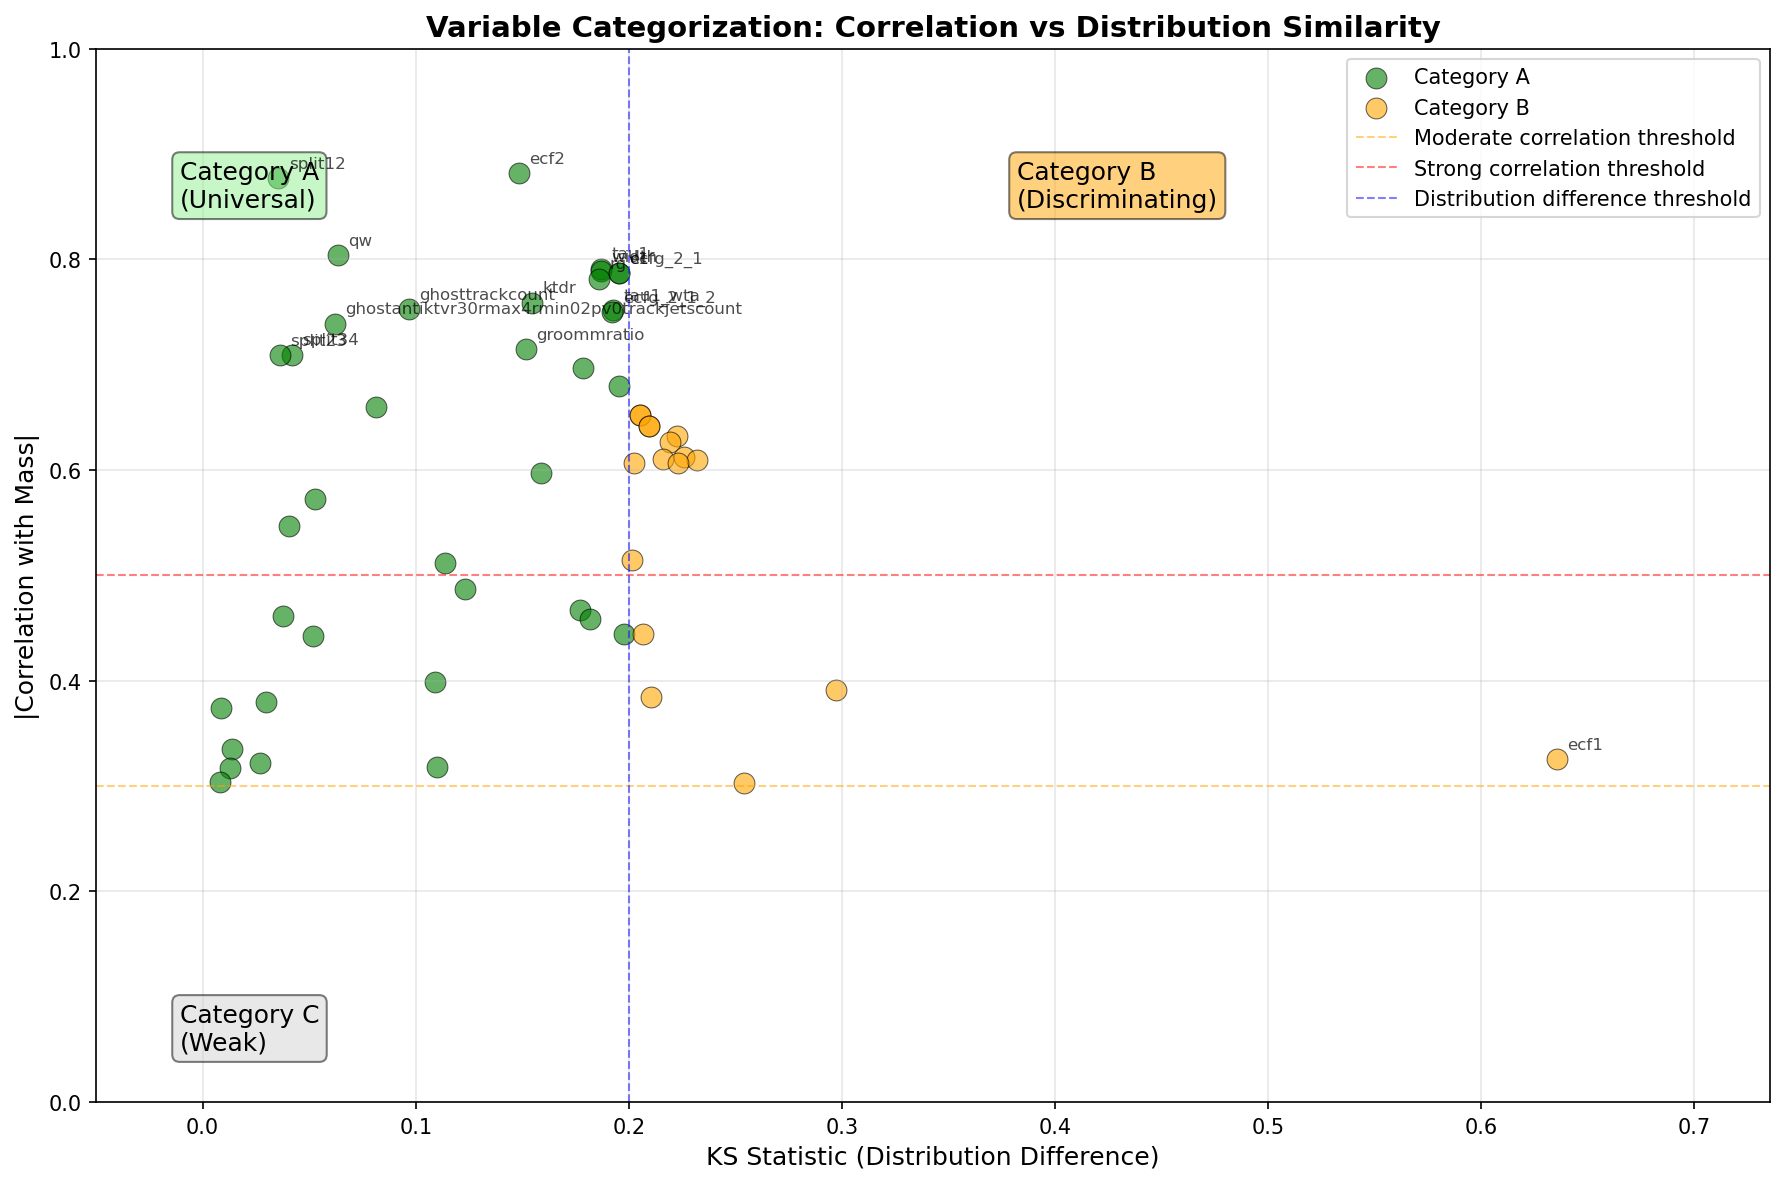

✓ Saved: variable_categorization_scatter.png


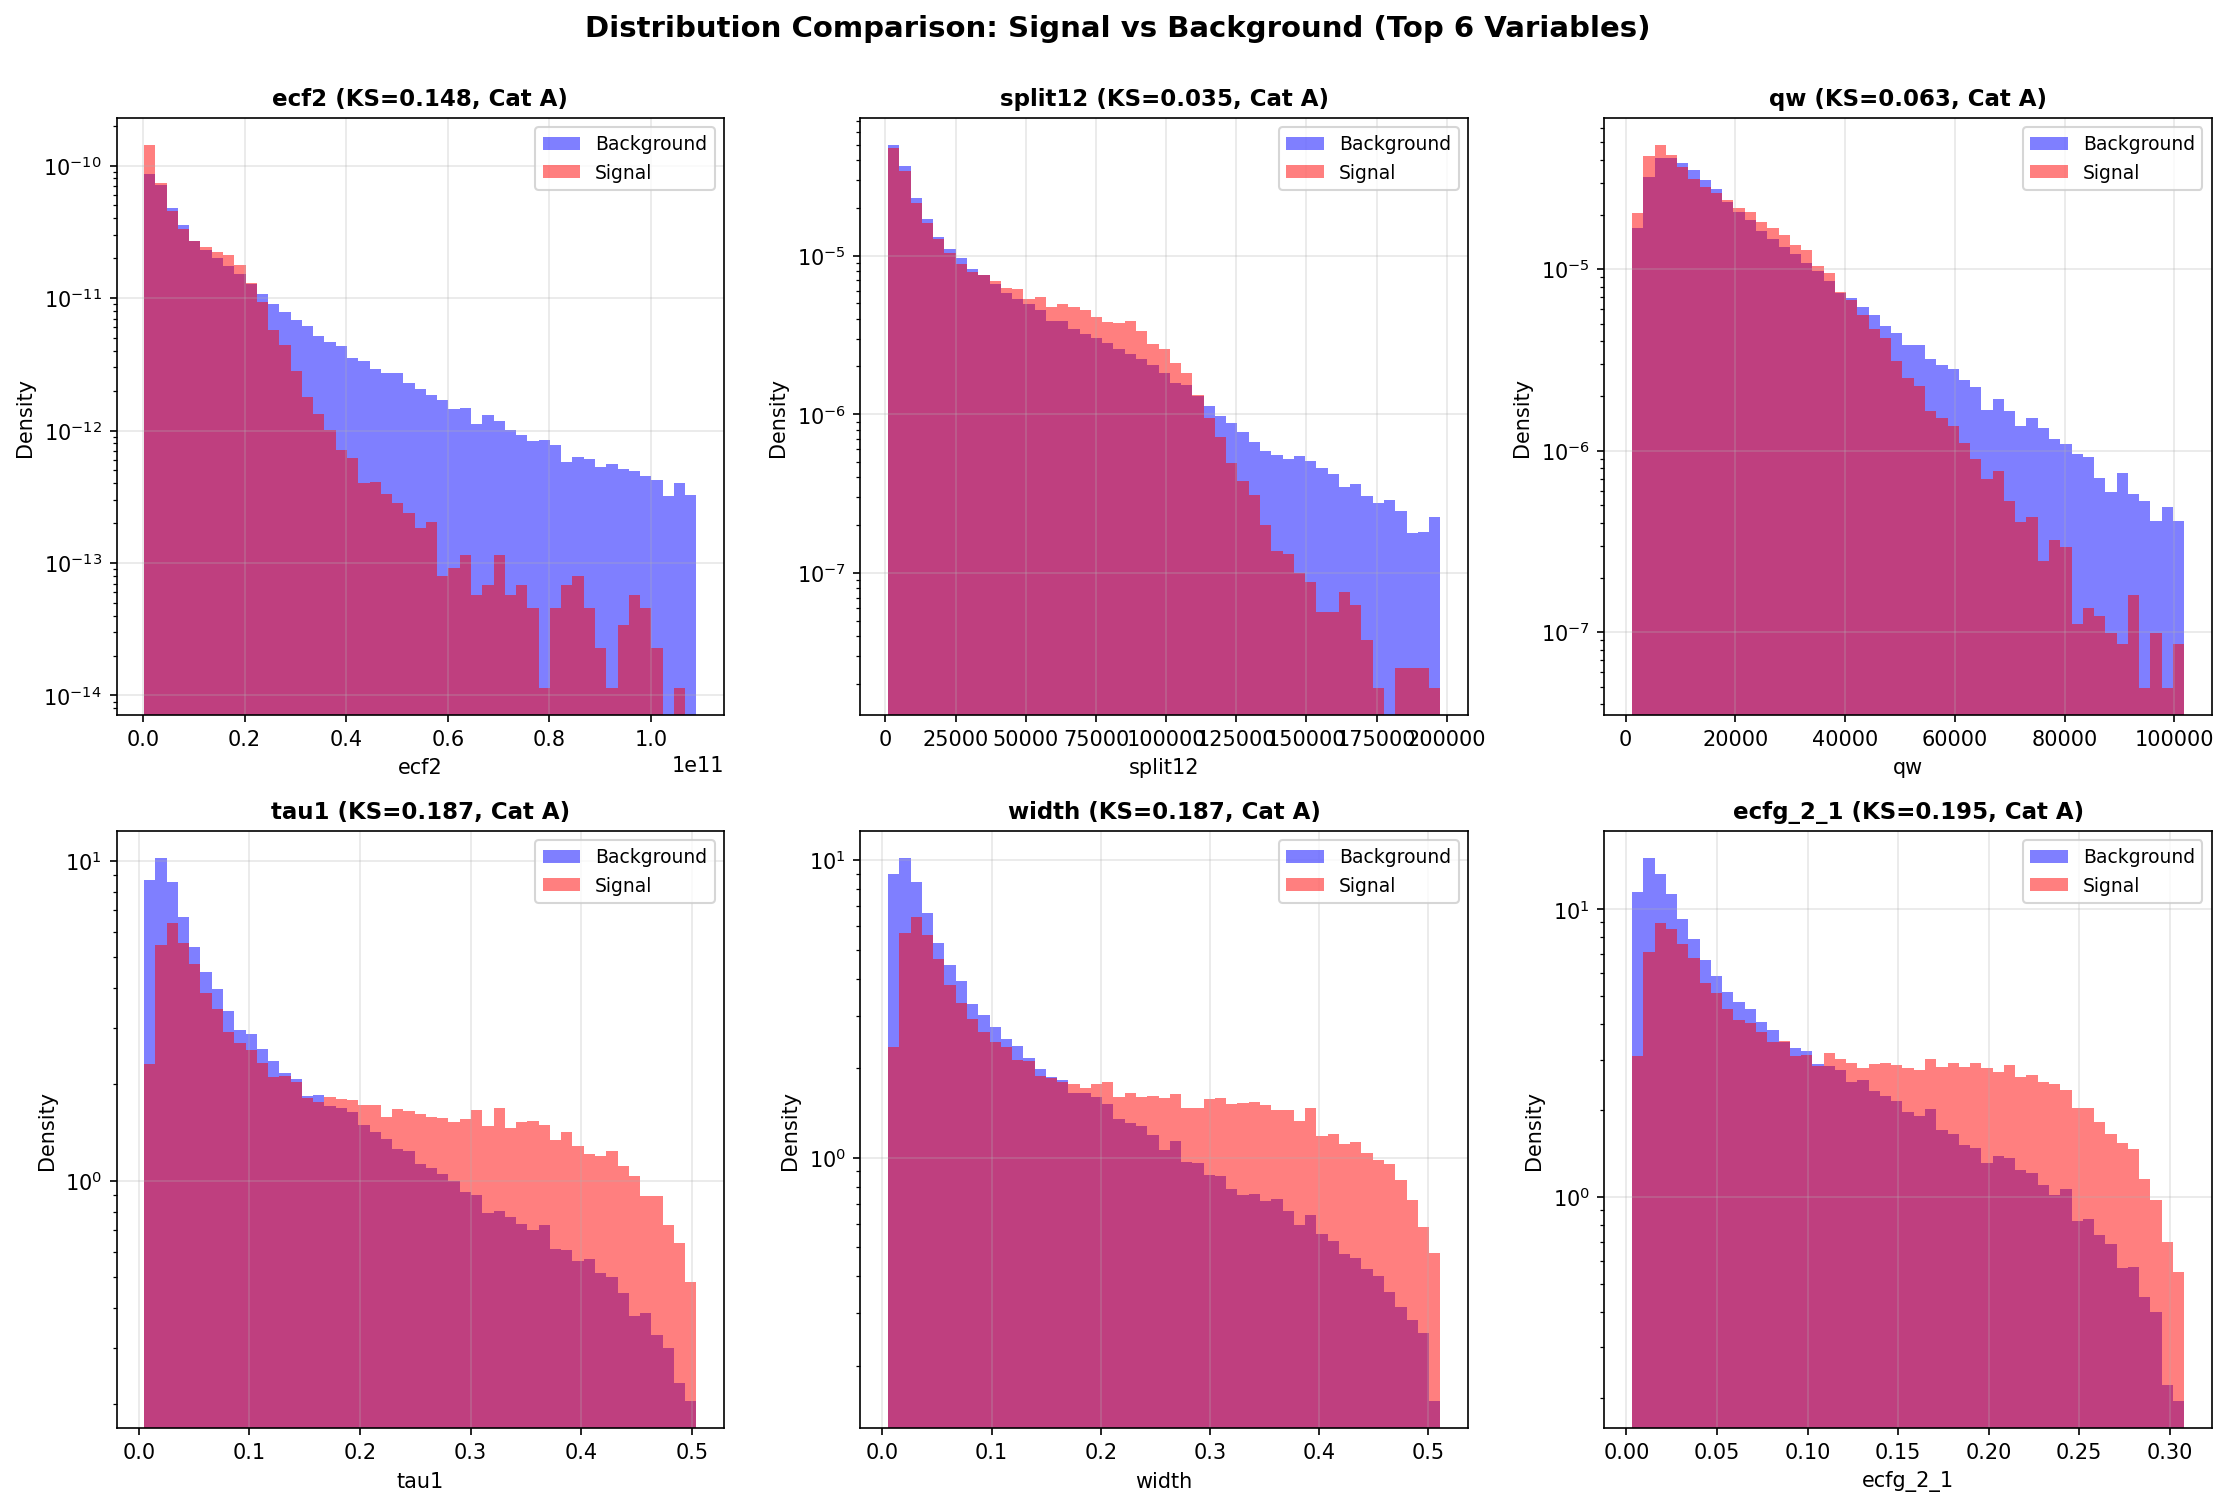

✓ Saved: distribution_comparison_top6.png

SUMMARY AND RECOMMENDATIONS

📊 Analysis Summary:
  • Total variables analyzed: 54
  • Category A (Universal): 37 variables
  • Category B (Discriminating): 17 variables

🎯 Recommended Variables for Modeling:

  PRIMARY INPUTS (Category A - top 5):
    • ecf2                 (r_bkg=+0.882, KS=0.148)
    • split12              (r_bkg=+0.877, KS=0.035)
    • qw                   (r_bkg=+0.804, KS=0.063)
    • tau1                 (r_bkg=+0.791, KS=0.187)
    • width                (r_bkg=+0.789, KS=0.187)

  CONDITIONING VARIABLES (Category B - if using Conditional GP/CGAN):
    • ecf1                 (r_bkg=+0.325, KS=0.635)
    • chargeptfrac         (r_bkg=+0.391, KS=0.297)
    • chargemfrac          (r_bkg=+0.303, KS=0.254)

💡 Modeling Strategy:
  1. Simple GP: Use top 4-5 Category A variables as inputs
     → Example: GP(mass | ecf2, split12, width, tau1)

  2. Conditional GP (if Category B variables exist):
     → Condition on Category B va

In [25]:
# ============================================================================
# Question 4: Signal vs Background Distribution Comparison (KS Test)
# ============================================================================

import pandas as pd
import numpy as np
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------------------------------------------------------
# Step 1: Load correlation results from Question 3
# ----------------------------------------------------------------------------

df = pd.read_csv('correlation_results_all_variables.csv')

print("="*80)
print("LOADING CORRELATION RESULTS FROM QUESTION 3")
print("="*80)

# Filter variables with |r| > 0.3 (correlated variables)
correlated_vars = df[df['Abs_Corr_Bkg'] > 0.3]

print(f"\nTotal variables with |r| > 0.3: {len(correlated_vars)}")
print(f"  Very Strong (|r| > 0.7): {len(df[df['Abs_Corr_Bkg'] > 0.7])}")
print(f"  Strong (0.5 < |r| < 0.7): {len(df[(df['Abs_Corr_Bkg'] > 0.5) & (df['Abs_Corr_Bkg'] <= 0.7)])}")
print(f"  Moderate (0.3 < |r| < 0.5): {len(df[(df['Abs_Corr_Bkg'] > 0.3) & (df['Abs_Corr_Bkg'] <= 0.5)])}")

# Get the list of variable names to test
variables_to_test = correlated_vars['Variable'].tolist()

print(f"\nVariables to analyze: {variables_to_test}")

# ----------------------------------------------------------------------------
# Step 2: Perform KS Test for each correlated variable
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("PERFORMING KOLMOGOROV-SMIRNOV TEST")
print("="*80)
print("\nComparing Signal vs Background distributions for each variable...")

# Store KS test results
ks_results = []

for var in variables_to_test:
    # Get data for this variable from leading jets (assumes you have these from Q3)
    # Note: leading_bkg and leading_sig should be available from your Question 3 code
    
    # Check if variable exists in your data
    if var not in leading_bkg or var not in leading_sig:
        print(f"Warning: {var} not found in data, skipping...")
        continue
    
    # Remove NaN and invalid values
    bkg_data = leading_bkg[var]
    sig_data = leading_sig[var]
    
    # Filter valid data
    valid_bkg = np.isfinite(bkg_data) & (bkg_data > -900)
    valid_sig = np.isfinite(sig_data) & (sig_data > -900)
    
    bkg_clean = bkg_data[valid_bkg]
    sig_clean = sig_data[valid_sig]
    
    # Check if enough data points
    if len(bkg_clean) < 100 or len(sig_clean) < 100:
        print(f"Warning: Not enough data for {var}, skipping...")
        continue
    
    # Perform KS test
    ks_stat, p_value = ks_2samp(sig_clean, bkg_clean)
    
    # Get correlations from dataframe
    corr_bkg = df[df['Variable'] == var]['Correlation_Background'].values[0]
    corr_sig = df[df['Variable'] == var]['Correlation_Signal'].values[0]
    
    # Store results
    ks_results.append({
        'Variable': var,
        'KS_Statistic': ks_stat,
        'P_Value': p_value,
        'Correlation_Bkg': corr_bkg,
        'Correlation_Sig': corr_sig,
        'Abs_Corr_Bkg': abs(corr_bkg),
        'Abs_Corr_Sig': abs(corr_sig)
    })

# Create DataFrame with results
df_ks = pd.DataFrame(ks_results)

print(f"\nSuccessfully analyzed {len(df_ks)} variables")

# ----------------------------------------------------------------------------
# Step 3: Interpret KS Test Results
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("KS TEST INTERPRETATION")
print("="*80)

print("\nKS Statistic Guidelines:")
print("  KS < 0.2  : Distributions are SIMILAR (small difference)")
print("  0.2 < KS < 0.4 : Distributions are MODERATELY DIFFERENT")
print("  KS > 0.4  : Distributions are VERY DIFFERENT")

# Display top 20 results sorted by KS statistic
print("\n" + "-"*80)
print("Top 20 Variables by Distribution Difference (KS Statistic)")
print("-"*80)
print(f"{'Variable':<25} {'KS Stat':<10} {'P-value':<12} {'Interpretation':<20}")
print("-"*80)

df_ks_sorted = df_ks.sort_values('KS_Statistic', ascending=False)

for idx, row in df_ks_sorted.head(20).iterrows():
    ks_stat = row['KS_Statistic']
    p_val = row['P_Value']
    
    if ks_stat < 0.2:
        interpretation = "Similar"
    elif ks_stat < 0.4:
        interpretation = "Moderately Different"
    else:
        interpretation = "Very Different"
    
    print(f"{row['Variable']:<25} {ks_stat:<10.3f} {p_val:<12.2e} {interpretation:<20}")

# ----------------------------------------------------------------------------
# Step 4: Categorize Variables (A, B, C)
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("VARIABLE CATEGORIZATION")
print("="*80)

print("\nCategory Definitions:")
print("  Category A (Universal): Correlated with mass + Similar distributions (KS < 0.2)")
print("    → Use for basic GP/CGAN modeling")
print("  Category B (Discriminating): Correlated with mass + Different distributions (KS ≥ 0.2)")
print("    → Use for conditional modeling or as conditioning variables")
print("  Category C (Weak): Not correlated with mass (|r| < 0.3)")
print("    → Not useful for mass prediction")

# Categorize based on correlation and KS statistic
def categorize_variable(row):
    """
    Categorize variables based on correlation and distribution similarity
    
    Category A: Strong/moderate correlation + similar distributions
    Category B: Strong/moderate correlation + different distributions  
    Category C: Weak correlation (already filtered out)
    """
    abs_corr = row['Abs_Corr_Bkg']
    ks_stat = row['KS_Statistic']
    
    # Check correlation strength
    if abs_corr > 0.5:  # Strong correlation
        if ks_stat < 0.2:
            return 'A'
        else:
            return 'B'
    elif abs_corr > 0.3:  # Moderate correlation
        if ks_stat < 0.2:
            return 'A'
        else:
            return 'B'
    else:  # Weak correlation (shouldn't happen as we filtered)
        return 'C'

df_ks['Category'] = df_ks.apply(categorize_variable, axis=1)

# Count by category
category_counts = df_ks['Category'].value_counts()

print("\n" + "-"*80)
print("Category Distribution")
print("-"*80)
for cat in ['A', 'B', 'C']:
    count = category_counts.get(cat, 0)
    print(f"Category {cat}: {count} variables")

# Display Category A variables (Universal predictors)
print("\n" + "="*80)
print("CATEGORY A - UNIVERSAL PREDICTORS")
print("="*80)
print("These variables can predict mass and have similar distributions in S and B")
print("→ Use as primary inputs for GP/CGAN modeling")
print("\n" + "-"*80)
print(f"{'Variable':<25} {'Corr_Bkg':<12} {'Corr_Sig':<12} {'KS Stat':<10}")
print("-"*80)

cat_a = df_ks[df_ks['Category'] == 'A'].sort_values('Abs_Corr_Bkg', ascending=False)
for idx, row in cat_a.iterrows():
    print(f"{row['Variable']:<25} {row['Correlation_Bkg']:>+.3f}       "
          f"{row['Correlation_Sig']:>+.3f}       {row['KS_Statistic']:>.3f}")

# Display Category B variables (Discriminating predictors)
print("\n" + "="*80)
print("CATEGORY B - DISCRIMINATING PREDICTORS")
print("="*80)
print("These variables can predict mass but distributions differ between S and B")
print("→ Use as conditioning variables for Conditional GP/CGAN")
print("\n" + "-"*80)
print(f"{'Variable':<25} {'Corr_Bkg':<12} {'Corr_Sig':<12} {'KS Stat':<10}")
print("-"*80)

cat_b = df_ks[df_ks['Category'] == 'B'].sort_values('KS_Statistic', ascending=False)
for idx, row in cat_b.iterrows():
    print(f"{row['Variable']:<25} {row['Correlation_Bkg']:>+.3f}       "
          f"{row['Correlation_Sig']:>+.3f}       {row['KS_Statistic']:>.3f}")

# ----------------------------------------------------------------------------
# Step 5: Save results to CSV
# ----------------------------------------------------------------------------

df_ks.to_csv('ks_test_results_and_categories.csv', index=False)
print(f"\n✓ Results saved to: ks_test_results_and_categories.csv")

# ----------------------------------------------------------------------------
# Step 6: Visualization 1 - Scatter Plot (Correlation vs KS Statistic)
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("CREATING VISUALIZATIONS")
print("="*80)

# Scatter plot: Correlation vs Distribution Difference
fig, ax = plt.subplots(figsize=(12, 8))

# Color by category
colors = {'A': 'green', 'B': 'orange', 'C': 'gray'}
for cat in ['A', 'B', 'C']:
    cat_data = df_ks[df_ks['Category'] == cat]
    if len(cat_data) > 0:
        ax.scatter(cat_data['KS_Statistic'], cat_data['Abs_Corr_Bkg'],
                  c=colors[cat], label=f'Category {cat}', s=100, alpha=0.6,
                  edgecolors='black', linewidth=0.5)

# Add threshold lines
ax.axhline(y=0.3, color='orange', linestyle='--', linewidth=1, alpha=0.5, 
           label='Moderate correlation threshold')
ax.axhline(y=0.5, color='red', linestyle='--', linewidth=1, alpha=0.5,
           label='Strong correlation threshold')
ax.axvline(x=0.2, color='blue', linestyle='--', linewidth=1, alpha=0.5,
           label='Distribution difference threshold')

# Add quadrant labels
ax.text(0.05, 0.85, 'Category A\n(Universal)', transform=ax.transAxes,
        fontsize=12, bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))
ax.text(0.55, 0.85, 'Category B\n(Discriminating)', transform=ax.transAxes,
        fontsize=12, bbox=dict(boxstyle='round', facecolor='orange', alpha=0.5))
ax.text(0.05, 0.05, 'Category C\n(Weak)', transform=ax.transAxes,
        fontsize=12, bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.5))

# Annotate key variables
for idx, row in df_ks.iterrows():
    if row['Abs_Corr_Bkg'] > 0.7 or row['KS_Statistic'] > 0.3:
        ax.annotate(row['Variable'], 
                   (row['KS_Statistic'], row['Abs_Corr_Bkg']),
                   xytext=(5, 5), textcoords='offset points',
                   fontsize=8, alpha=0.7)

ax.set_xlabel('KS Statistic (Distribution Difference)', fontsize=12)
ax.set_ylabel('|Correlation with Mass|', fontsize=12)
ax.set_title('Variable Categorization: Correlation vs Distribution Similarity',
            fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_xlim(-0.05, max(df_ks['KS_Statistic']) + 0.1)
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig('variable_categorization_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved: variable_categorization_scatter.png")

# ----------------------------------------------------------------------------
# Step 7: Visualization 2 - Distribution Comparison (Top 6 Variables)
# ----------------------------------------------------------------------------

# Select top 6 correlated variables for detailed comparison
top_6_vars = df_ks.sort_values('Abs_Corr_Bkg', ascending=False).head(6)['Variable'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, var in enumerate(top_6_vars):
    ax = axes[i]
    
    # Get data
    bkg_data = leading_bkg[var]
    sig_data = leading_sig[var]
    
    # Clean data
    valid_bkg = np.isfinite(bkg_data) & (bkg_data > -900)
    valid_sig = np.isfinite(sig_data) & (sig_data > -900)
    
    bkg_clean = bkg_data[valid_bkg]
    sig_clean = sig_data[valid_sig]
    
    # Get KS statistic for this variable
    ks_stat = df_ks[df_ks['Variable'] == var]['KS_Statistic'].values[0]
    cat = df_ks[df_ks['Variable'] == var]['Category'].values[0]
    
    # Calculate percentiles for binning (to handle outliers)
    p1_bkg, p99_bkg = np.percentile(bkg_clean, [1, 99])
    p1_sig, p99_sig = np.percentile(sig_clean, [1, 99])
    vmin = min(p1_bkg, p1_sig)
    vmax = max(p99_bkg, p99_sig)
    
    # Create histogram
    bins = np.linspace(vmin, vmax, 50)
    
    ax.hist(bkg_clean, bins=bins, alpha=0.5, label='Background',
            color='blue', density=True, histtype='stepfilled')
    ax.hist(sig_clean, bins=bins, alpha=0.5, label='Signal',
            color='red', density=True, histtype='stepfilled')
    
    ax.set_xlabel(var, fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.set_title(f'{var} (KS={ks_stat:.3f}, Cat {cat})',
                fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3)

plt.suptitle('Distribution Comparison: Signal vs Background (Top 6 Variables)',
            fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('distribution_comparison_top6.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved: distribution_comparison_top6.png")

# ----------------------------------------------------------------------------
# Step 8: Summary and Recommendations
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("SUMMARY AND RECOMMENDATIONS")
print("="*80)

print(f"\n📊 Analysis Summary:")
print(f"  • Total variables analyzed: {len(df_ks)}")
print(f"  • Category A (Universal): {len(cat_a)} variables")
print(f"  • Category B (Discriminating): {len(cat_b)} variables")

print(f"\n🎯 Recommended Variables for Modeling:")
print(f"\n  PRIMARY INPUTS (Category A - top 5):")
top_5_cat_a = cat_a.head(5)
for idx, row in top_5_cat_a.iterrows():
    print(f"    • {row['Variable']:<20} (r_bkg={row['Correlation_Bkg']:+.3f}, KS={row['KS_Statistic']:.3f})")

if len(cat_b) > 0:
    print(f"\n  CONDITIONING VARIABLES (Category B - if using Conditional GP/CGAN):")
    top_3_cat_b = cat_b.head(3)
    for idx, row in top_3_cat_b.iterrows():
        print(f"    • {row['Variable']:<20} (r_bkg={row['Correlation_Bkg']:+.3f}, KS={row['KS_Statistic']:.3f})")

print(f"\n💡 Modeling Strategy:")
print(f"  1. Simple GP: Use top 4-5 Category A variables as inputs")
print(f"     → Example: GP(mass | ecf2, split12, width, tau1)")
print(f"\n  2. Conditional GP (if Category B variables exist):")
print(f"     → Condition on Category B variables to account for different jet types")
print(f"     → Example: GP(mass | ecf2, split12 | phbb)")
print(f"\n  3. CGAN: Use Category A as generator inputs, Category B as conditions")

print("\n" + "="*80)
print("QUESTION 4 COMPLETE")
print("="*80)
print(f"\nOutput files:")
print(f"  • ks_test_results_and_categories.csv")
print(f"  • variable_categorization_scatter.png")
print(f"  • distribution_comparison_top6.png")

In [21]:
def compute_all_correlations(data_dict, variables, target='mass', n_sample=10000):
    """
    对多个变量计算 Pearson, Spearman, MutualInfo, DistanceCorr。
    
    n_sample: 距离相关计算量大，对数据抽样（不影响结论）
    """
    mass = data_dict[target]
    results = []
    
    for var in variables:
        if var == target:
            continue
        
        vals = data_dict[var]
        
        # 过滤无效值
        valid = np.isfinite(vals) & np.isfinite(mass) & (vals > -900)
        if np.sum(valid) < 100:
            continue
        
        x = vals[valid]
        y = mass[valid]
        
        # --- Pearson ---
        pearson_r, _ = pearsonr(x, y)
        
        # --- Spearman ---
        spearman_r, _ = spearmanr(x, y)
        
        # --- Mutual Information ---
        # 注意: MI 返回的是 nats（非负），需要归一化比较
        mi = mutual_info_regression(
            x.reshape(-1, 1), y, n_neighbors=5, random_state=42
        )[0]
        
        # --- Distance Correlation ---
        if HAS_DCOR:
            # 抽样加速
            n = min(n_sample, len(x))
            idx = np.random.choice(len(x), n, replace=False)
            dc = dcor.distance_correlation(x[idx], y[idx])
        else:
            dc = np.nan
        
        results.append({
            'variable': var,
            'pearson':   abs(pearson_r),
            'spearman':  abs(spearman_r),
            'mutual_info': mi,
            'distance_corr': dc,
            'n_valid': np.sum(valid)
        })
        
        print(f"  {var:<20} Pearson={abs(pearson_r):.3f}  "
              f"Spearman={abs(spearman_r):.3f}  "
              f"MI={mi:.3f}  "
              f"DistCorr={dc:.3f if not np.isnan(dc) else 'N/A'}")
    
    return pd.DataFrame(results)

# 选取有代表性的变量（全部运行会很慢）
# 你可以从 df_corr 取前20个最相关变量
top_vars_for_nl = very_strong + strong[:5] + medium[:3] + ['pt', 'eta', 'phi']
# 去重并确保变量在 leading_bkg 中存在
top_vars_for_nl = [v for v in dict.fromkeys(top_vars_for_nl) 
                   if v in leading_bkg]

print(f"分析 {len(top_vars_for_nl)} 个变量...")
print("="*80)

nl_results_bkg = compute_all_correlations(leading_bkg, top_vars_for_nl)

print(f"\n✅ 完成! 分析了 {len(nl_results_bkg)} 个变量")

NameError: name 'very_strong' is not defined